# 1. GIỚI THIỆU

**WESAD (WEarable Stress and Affect Detection)** là bộ dữ liệu công khai được xây dựng nhằm nghiên cứu khả năng nhận diện trạng thái căng thẳng và cảm xúc thông qua các tín hiệu sinh lý và chuyển động thu thập từ thiết bị đeo.

Bộ dữ liệu bao gồm 15 người tham gia (subjects), được ghi nhận trong các giai đoạn thí nghiệm như Baseline (trạng thái nền), Stress (căng thẳng), Amusement (hứng thú) và Meditation (thiền).

## 1.1. Thiết bị và tín hiệu thu thập

WESAD sử dụng hai thiết bị đeo:

- **RespiBAN Professional (ngực):** Ghi nhận ACC, ECG, EMG, EDA, Temp và Resp với tần số lấy mẫu 700 Hz.
- **Empatica E4 (cổ tay):** Ghi nhận ACC (32 Hz), BVP (64 Hz), EDA (4 Hz) và TEMP (4 Hz).

Tổng cộng có 10 loại tín hiệu theo thiết bị, tương ứng 14 kênh dữ liệu số, trong đó mỗi tín hiệu ACC gồm ba trục X, Y và Z.



## 1.2. Ý nghĩa của các tín hiệu đo

Bộ dữ liệu WESAD ghi nhận các tín hiệu sinh lý và chuyển động từ hai thiết bị RespiBAN Professional (ngực) và Empatica E4 (cổ tay). Mỗi tín hiệu phản ánh một khía cạnh khác nhau của hoạt động cơ thể, cung cấp thông tin phục vụ nghiên cứu nhận diện trạng thái căng thẳng và cảm xúc.

### a. Tín hiệu từ thiết bị RespiBAN (ngực)

| Tín hiệu | Tên đầy đủ | Ý nghĩa |
|---|---|---|
| ACC | Accelerometer | Đo gia tốc theo ba trục X, Y, Z, phản ánh chuyển động và tư thế của cơ thể. |
| ECG | Electrocardiogram | Ghi nhận hoạt động điện của tim, có thể khai thác thông tin về nhịp tim và biến thiên nhịp tim. |
| EMG | Electromyogram | Ghi nhận hoạt động điện của cơ, cung cấp thông tin liên quan đến sự co cơ và hoạt động cơ bắp. |
| EDA | Electrodermal Activity | Đo độ dẫn điện của da, phản ánh những thay đổi liên quan đến hoạt động của tuyến mồ hôi và hệ thần kinh giao cảm. |
| Temp | Skin Temperature | Ghi nhận nhiệt độ da tại vị trí đo, có thể chịu ảnh hưởng của phản ứng sinh lý và môi trường. |
| Resp | Respiration | Ghi nhận hoạt động hô hấp, cung cấp thông tin về nhịp thở và sự thay đổi của chu kỳ hít vào, thở ra. |

### b. Tín hiệu từ thiết bị Empatica E4 (cổ tay)

| Tín hiệu | Tên đầy đủ | Ý nghĩa |
|---|---|---|
| ACC | Accelerometer | Đo gia tốc theo ba trục X, Y, Z, phản ánh chuyển động của cổ tay. |
| BVP | Blood Volume Pulse | Ghi nhận dao động liên quan đến thể tích máu ngoại vi theo nhịp mạch bằng cảm biến quang học. |
| EDA | Electrodermal Activity | Đo độ dẫn điện của da tại cổ tay, cung cấp thông tin về những thay đổi liên quan đến hoạt động của hệ thần kinh giao cảm. |
| TEMP | Skin Temperature | Ghi nhận nhiệt độ da tại cổ tay và sự biến thiên theo thời gian. |

**Nhận xét:** Các tín hiệu cung cấp những nguồn thông tin bổ sung cho nhau, bao gồm hoạt động tim mạch, hô hấp, hoạt động cơ, độ dẫn điện của da, nhiệt độ và chuyển động. Tuy nhiên, sự thay đổi của một tín hiệu đơn lẻ không đủ để khẳng định trạng thái căng thẳng, vì tín hiệu sinh lý còn chịu ảnh hưởng từ nhiều yếu tố khác.


# 2. DỮ LIỆU

## 2.1. Nguồn dữ liệu và phạm vi phân tích

Bộ dữ liệu WESAD cung cấp dữ liệu của **15 người tham gia (subjects)**, mỗi người được lưu trong một thư mục riêng và có một tệp `SX.pkl` tương ứng.

Danh sách các subject gồm:

`S2, S3, S4, S5, S6, S7, S8, S9, S10, S11, S13, S14, S15, S16, S17`.

Trong notebook này, dữ liệu được đọc trực tiếp từ các tệp `.pkl` tại thư mục:

`data/raw/WESAD/`

Mỗi tệp `.pkl` chứa ba thành phần chính:

- **`signal`:** Các tín hiệu sinh lý và chuyển động thu thập từ hai thiết bị RespiBAN và Empatica E4.
- **`label`:** Dãy nhãn biểu diễn các giai đoạn thí nghiệm theo thời gian.
- **`subject`:** Mã định danh người tham gia.


## 2.2. Load dữ liệu

Bộ dữ liệu WESAD gồm 15 người tham gia (subjects), mỗi người có một tệp `.pkl` chứa các tín hiệu cảm biến và nhãn trạng thái theo thời gian.

Ở bước này, tiến hành đọc lần lượt 15 tệp `.pkl` nhằm:

- Xác nhận các tệp dữ liệu tồn tại và có thể đọc được.
- Kiểm tra mã định danh của từng subject.
- Xác định các thành phần chính của dữ liệu.
- Ghi nhận số lượng mẫu nhãn và thời lượng ghi nhận của từng subject.

Do dung lượng dữ liệu tương đối lớn, các tệp được đọc **tuần tự**, chỉ giữ thông tin tổng hợp của mỗi subject thay vì lưu toàn bộ dữ liệu của 15 người đồng thời trong RAM.

Bước này chỉ đọc và khảo sát dữ liệu gốc, chưa thực hiện tiền xử lý hay biến đổi dữ liệu.

In [2]:
from pathlib import Path
import pickle
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Danh sách 15 subject WESAD
SUBJECT_IDS = [
    "S2", "S3", "S4", "S5", "S6",
    "S7", "S8", "S9", "S10", "S11",
    "S13", "S14", "S15", "S16", "S17"
]

# Đường dẫn thư mục dữ liệu
candidates = [
    Path("../data/raw/WESAD"),
    Path("data/raw/WESAD")
]

WESAD_ROOT = next(
    (path.resolve() for path in candidates if path.is_dir()),
    None
)

if WESAD_ROOT is None:
    raise FileNotFoundError("Không tìm thấy thư mục dữ liệu WESAD")

print("Thư mục dữ liệu:", WESAD_ROOT)
print("Số subject cần đọc:", len(SUBJECT_IDS))

Thư mục dữ liệu: D:\Deep_learning_group\Projects\DL13-WESAD\data\raw\WESAD
Số subject cần đọc: 15


In [3]:
from IPython.display import display
summary = []

for subject_id in SUBJECT_IDS:
    file_path = WESAD_ROOT / subject_id / f"{subject_id}.pkl"

    if not file_path.is_file():
        print(f"[THIẾU] {subject_id}")
        continue

    # Chỉ đọc pickle từ bộ WESAD đáng tin cậy
    with open(file_path, "rb") as f:
        data = pickle.load(f, encoding="latin1")

    # Thông tin tổng quan
    labels = data["label"]
    signals = data["signal"]

    summary.append({
        "Subject": data["subject"],
        "Chest signals": len(signals["chest"]),
        "Wrist signals": len(signals["wrist"]),
        "Label samples": len(labels),
        "Duration (minutes)": len(labels) / 700 / 60
    })

    print(f"[OK] Đã đọc {subject_id}")

    # Giải phóng dữ liệu trước khi đọc subject tiếp theo
    del data, labels, signals
    gc.collect()

df_summary = pd.DataFrame(summary)

display(df_summary)
print(f"Đã đọc thành công: {len(df_summary)}/{len(SUBJECT_IDS)} subject")

[OK] Đã đọc S2
[OK] Đã đọc S3
[OK] Đã đọc S4
[OK] Đã đọc S5
[OK] Đã đọc S6
[OK] Đã đọc S7
[OK] Đã đọc S8
[OK] Đã đọc S9
[OK] Đã đọc S10
[OK] Đã đọc S11
[OK] Đã đọc S13
[OK] Đã đọc S14
[OK] Đã đọc S15
[OK] Đã đọc S16
[OK] Đã đọc S17


,Subject,Chest signals,Wrist signals,Label samples,Duration (minutes)
0,S2,6,4,4255300,101.316667
1,S3,6,4,4545100,108.216667
2,S4,6,4,4496100,107.050000
3,S5,6,4,4380600,104.300000
4,S6,6,4,4949700,117.850000
5,S7,6,4,3666600,87.300000
6,S8,6,4,3826200,91.100000
7,S9,6,4,3656100,87.050000
8,S10,6,4,3847200,91.600000
9,S11,6,4,3663100,87.216667


Đã đọc thành công: 15/15 subject


**Nhận xét**

Quá trình đọc dữ liệu đã thực hiện thành công trên toàn bộ **15 subject** của bộ dữ liệu WESAD.

Kết quả cho thấy:

- Mỗi subject đều có 6 loại tín hiệu từ thiết bị RespiBAN (ngực) và 4 loại tín hiệu từ Empatica E4 (cổ tay).
- Số lượng mẫu nhãn (`Label samples`) khác nhau giữa các subject.
- Subject S6 có thời lượng ghi nhận dài nhất (117,85 phút), trong khi S9 có thời lượng ngắn nhất (87,05 phút).
- Subject S2 có 4.255.300 mẫu nhãn, tương ứng khoảng 101,32 phút.

thời lượng ghi nhận (Duration): là thời lượng của bản ghi dữ liệu, được xác định dựa trên số lượng mẫu và tần số lấy mẫu (*sampling rate*).

Công thức tổng quát:

$$
T_{\text{giây}} = \frac{N}{f_s}
$$

Trong đó:

- $T_{\text{giây}}$: Thời lượng ghi nhận, đơn vị giây.
- $N$: Tổng số mẫu (*samples*) của tín hiệu.
- $f_s$: Tần số lấy mẫu (*sampling rate*), đơn vị Hz (số mẫu/giây).

Để đổi từ giây sang phút:

$$
T_{\text{phút}} = \frac{N}{f_s \times 60}
$$

Trong bộ dữ liệu WESAD, mảng `label` có tần số lấy mẫu **700 Hz**, tức là mỗi giây có 700 giá trị nhãn.

Do đó, thời lượng của mỗi subject được tính bằng:

$$
T_{\text{phút}} = \frac{N_{\text{label}}}{700 \times 60}
$$

Trong đó:
- $N_{\text{label}}$: Số phần tử trong mảng `label`.
- $700$: Tần số lấy mẫu của nhãn (700 mẫu/giây).
- $60$: Số giây trong một phút.

**Ví dụ với subject S2:**

$$
T_{\text{giây}} = \frac{4.255.300}{700} = 6.079 \text{ giây}
$$

$$
T_{\text{phút}} = \frac{6.079}{60} \approx 101,32 \text{ phút}
$$

Tương đương 1 giờ 41 phút 19 giây.

**Lưu ý:** Các tín hiệu có thể có tần số lấy mẫu khác nhau. Khi tính thời lượng từ một tín hiệu cụ thể, phải sử dụng đúng tần số của tín hiệu đó:

| Tín hiệu | Tần số lấy mẫu |
|---|---:|
| Các tín hiệu ngực và `label` | 700 Hz |
| ACC cổ tay | 32 Hz |
| BVP cổ tay | 64 Hz |
| EDA và TEMP cổ tay | 4 Hz |

**Kết luận:** Cả 15 subject đều có cấu trúc nhóm tín hiệu tương đồng, nhưng thời lượng ghi nhận khác nhau. Kết quả này mới phản ánh thông tin tổng quan của dữ liệu, chưa đủ để đánh giá chất lượng các tín hiệu bên trong.


In [4]:
structure_rows = []

for subject_id in SUBJECT_IDS:
    file_path = WESAD_ROOT / subject_id / f"{subject_id}.pkl"

    if not file_path.is_file():
        continue

    with open(file_path, "rb") as f:
        data = pickle.load(f, encoding="latin1")

    # Duyệt hai thiết bị: chest và wrist
    for device, signals in data["signal"].items():

        # Duyệt các tín hiệu của từng thiết bị
        for signal_name, values in signals.items():

            structure_rows.append({
                "Subject": subject_id,
                "Device": device,
                "Signal": signal_name,
                "Shape": values.shape,
                "Dtype": str(values.dtype),
                "Samples": values.shape[0],
                "Channels": values.shape[1]
            })

    # Ghi nhận cấu trúc mảng nhãn
    labels = data["label"]

    structure_rows.append({
        "Subject": subject_id,
        "Device": "-",
        "Signal": "label",
        "Shape": labels.shape,
        "Dtype": str(labels.dtype),
        "Samples": len(labels),
        "Channels": 1
    })

    del data, labels
    gc.collect()

# Chuyển kết quả thành DataFrame
df_structure = pd.DataFrame(structure_rows)

# Xem chi tiết cấu trúc của S2
print("CẤU TRÚC DỮ LIỆU SUBJECT S2")
display(df_structure[df_structure["Subject"] == "S2"])

# Tổng hợp thông tin cấu trúc của cả 15 subject
df_check = (
    df_structure.groupby("Subject")
    .agg(
        Total_arrays=("Signal", "count"),
        Total_channels=("Channels", "sum"),
        Total_samples_label=(
            "Samples",
            lambda x: x.iloc[-1]
        )
    )
    .reset_index()
)

print("TỔNG HỢP CẤU TRÚC 15 SUBJECT")
display(df_check)

CẤU TRÚC DỮ LIỆU SUBJECT S2


,Subject,Device,Signal,Shape,Dtype,Samples,Channels
0,S2,chest,ACC,"(4255300, 3)",float64,4255300,3
1,S2,chest,ECG,"(4255300, 1)",float64,4255300,1
2,S2,chest,EMG,"(4255300, 1)",float64,4255300,1
3,S2,chest,EDA,"(4255300, 1)",float64,4255300,1
4,S2,chest,Temp,"(4255300, 1)",float32,4255300,1
5,S2,chest,Resp,"(4255300, 1)",float64,4255300,1
6,S2,wrist,ACC,"(194528, 3)",float64,194528,3
7,S2,wrist,BVP,"(389056, 1)",float64,389056,1
8,S2,wrist,EDA,"(24316, 1)",float64,24316,1
9,S2,wrist,TEMP,"(24316, 1)",float64,24316,1


TỔNG HỢP CẤU TRÚC 15 SUBJECT


,Subject,Total_arrays,Total_channels,Total_samples_label
0,S10,11,15,3847200
1,S11,11,15,3663100
2,S13,11,15,3875900
3,S14,11,15,3883600
4,S15,11,15,3676400
5,S16,11,15,3941700
6,S17,11,15,4144000
7,S2,11,15,4255300
8,S3,11,15,4545100
9,S4,11,15,4496100


Kết quả kiểm tra cấu trúc dữ liệu của 15 subject cho thấy:

- Mỗi subject có **11 mảng dữ liệu**, bao gồm 10 mảng tín hiệu cảm biến và một mảng nhãn (`label`).
- Tổng cộng có **14 kênh tín hiệu số** và một mảng nhãn riêng biệt.
- Các tín hiệu ACC có dạng mảng hai chiều `(N, 3)`, tương ứng với ba trục gia tốc X, Y, Z.
- Các tín hiệu còn lại có dạng `(N, 1)`, biểu diễn một giá trị đo tại mỗi lần lấy mẫu.
- Mảng `label` có dạng `(N,)`, là mảng một chiều chứa các mã nhãn trạng thái.

**Ý nghĩa của các thuộc tính:**

| Thuộc tính | Ý nghĩa |
|---|---|
| `shape` | Kích thước của mảng NumPy theo từng chiều. |
| `dtype` | Kiểu dữ liệu của các phần tử trong mảng. |
| `Samples` | Số lần lấy mẫu, tương ứng với số hàng của mảng tín hiệu. |
| `Channels` | Số kênh giá trị được ghi nhận tại mỗi lần lấy mẫu. |

Các tín hiệu chủ yếu sử dụng kiểu dữ liệu `float64`, riêng tín hiệu nhiệt độ ngực của S2 sử dụng `float32`. Mảng nhãn sử dụng `int32` để lưu các mã trạng thái dưới dạng số nguyên.

Số lượng mẫu nhãn khác nhau giữa các subject, phù hợp với kết quả khảo sát thời lượng ghi nhận trước đó.

**Kết luận:** Cả 15 subject đều có cùng số lượng mảng và kênh dữ liệu. Tuy nhiên, cần đối chiếu chi tiết kích thước và kiểu dữ liệu của từng tín hiệu giữa các subject để xác minh tính nhất quán về cấu trúc.

In [5]:
# Đặc tả: (thiết bị, tín hiệu) -> (sampling rate, channels)
signal_specs = {
    ("chest", "ACC"): (700, 3),
    ("chest", "ECG"): (700, 1),
    ("chest", "EMG"): (700, 1),
    ("chest", "EDA"): (700, 1),
    ("chest", "Temp"): (700, 1),
    ("chest", "Resp"): (700, 1),
    ("wrist", "ACC"): (32, 3),
    ("wrist", "BVP"): (64, 1),
    ("wrist", "EDA"): (4, 1),
    ("wrist", "TEMP"): (4, 1),
    ("-", "label"): (700, 1)
}

# Lấy số mẫu nhãn của mỗi subject làm mốc thời gian
label_samples = (
    df_structure[df_structure["Signal"] == "label"]
    .set_index("Subject")["Samples"]
    .to_dict()
)

check_rows = []

for _, row in df_structure.iterrows():
    subject = row["Subject"]
    device = row["Device"]
    signal = row["Signal"]

    # Tần số và số kênh kỳ vọng
    fs, channels = signal_specs[(device, signal)]

    # Số mẫu kỳ vọng từ thời lượng của label
    expected_samples = round(
        label_samples[subject] / 700 * fs
    )

    # Shape kỳ vọng
    if signal == "label":
        expected_shape = (expected_samples,)
    else:
        expected_shape = (expected_samples, channels)

    check_rows.append({
        "Subject": subject,
        "Device": device,
        "Signal": signal,
        "Sampling rate (Hz)": fs,
        "Actual shape": row["Shape"],
        "Expected shape": expected_shape,
        "Dtype": row["Dtype"],
        "Shape OK": row["Shape"] == expected_shape
    })

df_consistency = pd.DataFrame(check_rows)

# Tổng hợp theo từng loại tín hiệu
df_consistency_summary = (
    df_consistency
    .groupby(["Device", "Signal"], sort=False)
    .agg(
        Subjects=("Subject", "nunique"),
        Dtypes=("Dtype", lambda x: ", ".join(sorted(x.unique()))),
        Shape_errors=("Shape OK", lambda x: (~x).sum())
    )
    .reset_index()
)

print("KIỂM TRA TÍNH NHẤT QUÁN CỦA CÁC TÍN HIỆU")
display(df_consistency_summary)

# Kiểm tra có thiếu loại tín hiệu nào không
missing_signals = []

for subject in SUBJECT_IDS:
    subject_data = df_structure[
        df_structure["Subject"] == subject
    ]

    actual_signals = set(
        zip(subject_data["Device"], subject_data["Signal"])
    )

    for signal_key in signal_specs:
        if signal_key not in actual_signals:
            missing_signals.append((subject, signal_key))

# Hiển thị kết quả kiểm tra
shape_errors = df_consistency[
    ~df_consistency["Shape OK"]
]

print("Số subject:", df_structure["Subject"].nunique())
print("Số tín hiệu bị thiếu:", len(missing_signals))
print("Số mảng sai shape:", len(shape_errors))

if missing_signals:
    print("Các tín hiệu bị thiếu:", missing_signals)

if not shape_errors.empty:
    display(shape_errors)


KIỂM TRA TÍNH NHẤT QUÁN CỦA CÁC TÍN HIỆU


,Device,Signal,Subjects,Dtypes,Shape_errors
0,chest,ACC,15,float64,0
1,chest,ECG,15,float64,0
2,chest,EMG,15,float64,0
3,chest,EDA,15,float64,0
4,chest,Temp,15,float32,0
5,chest,Resp,15,float64,0
6,wrist,ACC,15,float64,0
7,wrist,BVP,15,float64,0
8,wrist,EDA,15,float64,0
9,wrist,TEMP,15,float64,0


Số subject: 15
Số tín hiệu bị thiếu: 0
Số mảng sai shape: 0


Kết quả kiểm tra trên toàn bộ 15 subject cho thấy:

- Cả 15 subject đều có đầy đủ 10 mảng tín hiệu cảm biến và một mảng nhãn.
- Không phát hiện trường hợp thiếu loại tín hiệu hoặc mảng nhãn (`Missing signals = 0`).
- Tất cả 165 mảng được kiểm tra đều có kích thước (`shape`) khớp với số mẫu kỳ vọng dựa trên tần số lấy mẫu và số kênh của từng tín hiệu (`Shape errors = 0`).
- Kiểu dữ liệu (`dtype`) của mỗi loại tín hiệu nhất quán giữa 15 subject: phần lớn sử dụng `float64`, riêng nhiệt độ ngực sử dụng `float32` và nhãn sử dụng `int32`.

**Kết luận:** Bộ dữ liệu WESAD có cấu trúc nhất quán giữa 15 subject về số lượng tín hiệu, số kênh, kiểu dữ liệu và số mẫu tương ứng với tần số lấy mẫu.

Tuy nhiên, kết quả này chỉ xác nhận tính nhất quán về cấu trúc, chưa phản ánh chất lượng của các giá trị tín hiệu. Việc kiểm tra giá trị thiếu, giá trị không hữu hạn và các giá trị bất thường sẽ được thực hiện trong giai đoạn khám phá và thống kê mô tả dữ liệu.

## 2.3. Thống kê mô tả

In [6]:
subject_statistics = {}

for subject_id in SUBJECT_IDS:

    file_path = WESAD_ROOT / subject_id / f"{subject_id}.pkl"

    with open(file_path, "rb") as f:
        data = pickle.load(f, encoding="latin1")

    statistics = {}

    # Duyệt các thiết bị và tín hiệu
    for device, signals in data["signal"].items():

        for signal_name, values in signals.items():

            # Thống kê riêng từng kênh
            for i in range(values.shape[1]):

                if signal_name == "ACC":
                    channel = f"{device}_ACC_{'XYZ'[i]}"
                else:
                    channel = f"{device}_{signal_name}"

                # Thống kê bằng Pandas describe()
                statistics[channel] = (
                    pd.Series(values[:, i]).describe()
                )

    # Tạo bảng describe cho subject hiện tại
    subject_statistics[subject_id] = pd.DataFrame(statistics)

    print(f"[OK] Đã thống kê {subject_id}")

    del data
    gc.collect()


# Ghép kết quả của 15 subject thành một DataFrame
df_describe_15 = pd.concat(
    subject_statistics,
    names=["Subject", "Statistic"]
)

print("THỐNG KÊ MÔ TẢ - 15 SUBJECT")
print("Kích thước bảng:", df_describe_15.shape)


with pd.option_context("display.max_rows", 130):
    display(df_describe_15.round(4))

[OK] Đã thống kê S2
[OK] Đã thống kê S3
[OK] Đã thống kê S4
[OK] Đã thống kê S5
[OK] Đã thống kê S6
[OK] Đã thống kê S7
[OK] Đã thống kê S8
[OK] Đã thống kê S9
[OK] Đã thống kê S10
[OK] Đã thống kê S11
[OK] Đã thống kê S13
[OK] Đã thống kê S14
[OK] Đã thống kê S15
[OK] Đã thống kê S16
[OK] Đã thống kê S17
THỐNG KÊ MÔ TẢ - 15 SUBJECT
Kích thước bảng: (120, 14)


chest_ACC_X   chest_ACC_Y   chest_ACC_Z     chest_ECG  \
Subject Statistic                                                           
S2      count      4.255300e+06  4.255300e+06  4.255300e+06  4.255300e+06   
        mean       7.539000e-01 -1.332000e-01 -4.227000e-01  1.200000e-03   
        std        1.751000e-01  6.420000e-02  3.002000e-01  1.541000e-01   
        min        2.150000e-01 -6.600000e-01 -1.135400e+00 -1.499500e+00   
        25%        6.210000e-01 -1.498000e-01 -7.172000e-01 -6.800000e-02   
        50%        8.568000e-01 -1.256000e-01 -3.222000e-01  8.200000e-03   
        75%        8.922000e-01 -9.580000e-02 -2.098000e-01  4.440000e-02   
        max        2.029800e+00  5.390000e-01  1.246800e+00  1.499300e+00   
S3      count      4.545100e+06  4.545100e+06  4.545100e+06  4.545100e+06   
        mean       8.588000e-01  1.000000e-03  3.270000e-02  8.000000e-04   
        std        7.470000e-02  7.000000e-02  3.137000e-01  2.961000e-01   
        min       -6.600000e+00 -6.600000e+00 -6.600000e+00 -1.500000e+00   
        25%        8.378000e-01 -3.700000e-02 -2.310000e-01 -1.387000e-01   
        50%        8.638000e-01 -5.400000e-03  1.740000e-02 -4.240000e-02   
        75%        9.020000e-01  3.340000e-02  2.946000e-01  3.030000e-02   
        max        2.981400e+00  1.322400e+00  4.508200e+00  1.500000e+00   
S4      count      4.496100e+06  4.496100e+06  4.496100e+06  4.496100e+06   
        mean       7.896000e-01 -2.364000e-01 -3.503000e-01  1.200000e-03   
        std        1.190000e-01  1.513000e-01  2.406000e-01  2.349000e-01   
        min       -9.800000e-03 -6.222000e-01 -1.440200e+00 -1.499400e+00   
        25%        7.198000e-01 -3.940000e-01 -4.962000e-01 -7.400000e-02   
        50%        8.062000e-01 -1.942000e-01 -3.800000e-01 -2.470000e-02   
        75%        8.958000e-01 -1.156000e-01 -1.704000e-01  8.600000e-03   
        max        1.694200e+00  4.690000e-01  1.947000e+00  1.500000e+00   
S5      count      4.380600e+06  4.380600e+06  4.380600e+06  4.380600e+06   
        mean       8.516000e-01 -4.040000e-02 -1.554000e-01  1.100000e-03   
        std        5.840000e-02  3.950000e-02  3.153000e-01  2.506000e-01   
        min       -1.008600e+00 -1.382600e+00 -4.781400e+00 -1.499400e+00   
        25%        8.232000e-01 -5.460000e-02 -4.210000e-01 -6.460000e-02   
        50%        8.518000e-01 -4.100000e-02 -3.002000e-01 -2.630000e-02   
        75%        9.034000e-01 -2.640000e-02  7.060000e-02  1.790000e-02   
        max        2.669200e+00  1.609000e+00  4.449000e+00  1.500000e+00   
S6      count      4.949700e+06  4.949700e+06  4.949700e+06  4.949700e+06   
        mean       7.101000e-01 -5.100000e-02 -4.129000e-01  7.000000e-04   
        std        1.245000e-01  5.830000e-02  4.362000e-01  3.036000e-01   
        min        2.490000e-01 -6.728000e-01 -3.468600e+00 -7.139000e-01   
        25%        5.962000e-01 -8.520000e-02 -7.426000e-01 -9.100000e-02   
        50%        7.006000e-01 -4.440000e-02 -6.246000e-01 -2.490000e-02   
        75%        8.290000e-01 -1.640000e-02 -2.286000e-01  2.010000e-02   
        max        1.844200e+00  5.590000e-01  2.284200e+00  1.500000e+00   
S7      count      3.666600e+06  3.666600e+06  3.666600e+06  3.666600e+06   
        mean       8.851000e-01 -3.940000e-02 -1.867000e-01  1.300000e-03   
        std        3.850000e-02  3.390000e-02  1.753000e-01  2.725000e-01   
        min        3.750000e-01 -6.220000e-01 -3.436600e+00 -1.164400e+00   
        25%        8.522000e-01 -5.700000e-02 -3.458000e-01 -8.240000e-02   
        50%        9.006000e-01 -3.540000e-02 -1.806000e-01 -3.070000e-02   
        75%        9.098000e-01 -2.060000e-02 -1.138000e-01  4.300000e-02   
        max        1.796600e+00  4.818000e-01  2.507000e+00  1.499500e+00   
S8      count      3.826200e+06  3.826200e+06  3.826200e+06  3.826200e+06   
        mean       8.247000e-01 -8.770000e-02 -2.707000e-01  1.500000e-03   
        std     

uá trình thống kê mô tả được thực hiện trên toàn bộ 15 subject, với 14 kênh tín hiệu cảm biến cho mỗi subject.

Kết quả thu được bảng gồm 120 hàng (15 subject × 8 chỉ số thống kê) và 14 cột tín hiệu.

**Các quan sát chính:**

1. **Số lượng mẫu:** Giá trị `count` của các kênh khớp với số mẫu đã kiểm tra ở mục 2.2. Chưa phát hiện giá trị NaN thông qua chỉ số này, nhưng cần kiểm tra riêng các giá trị vô cực (Inf).

2. **Sự khác biệt giữa các subject:** Các chỉ số trung bình, độ lệch chuẩn và phân vị có sự khác biệt giữa các cá nhân. Ví dụ, mean của EDA cổ tay ở S14 là 0.3143, trong khi S13 là 7.0936.

3. **Giá trị nhiệt độ bất thường:** Tín hiệu `chest_Temp` của S3 có giá trị nhỏ nhất là -273.15, không phù hợp với nhiệt độ cơ thể nếu đơn vị đo là °C.

4. **Giá trị gia tốc đáng chú ý:** Ba trục `chest_ACC_X`, `chest_ACC_Y` và `chest_ACC_Z` của S3 đều có giá trị nhỏ nhất là -6.6. Cần kiểm tra thêm để xác định nguồn gốc của giá trị này.

5. **Biên độ BVP:** Một số subject có giá trị BVP cực tiểu và cực đại với độ lớn đáng kể. Ví dụ, S5 có giá trị BVP từ -1773.76 đến 1789.00.

**Kết luận:**

Thống kê mô tả cho thấy dữ liệu có sự khác biệt giữa các subject và tồn tại những giá trị cực trị đáng chú ý.

Tuy nhiên, các chỉ số thống kê chưa đủ để xác định toàn bộ chất lượng tín hiệu. Cần tiếp tục kiểm tra giá trị không hợp lệ và trực quan hóa dữ liệu trước khi quyết định phương pháp tiền xử lý.

Ở giai đoạn này, dữ liệu gốc chưa bị thay đổi.

In [7]:
invalid_rows = []

for subject_id in SUBJECT_IDS:
    file_path = WESAD_ROOT / subject_id / f"{subject_id}.pkl"

    with open(file_path, "rb") as f:
        data = pickle.load(f, encoding="latin1")

    for device, signals in data["signal"].items():
        for signal_name, values in signals.items():

            for i in range(values.shape[1]):

                if signal_name == "ACC":
                    channel = f"{device}_ACC_{'XYZ'[i]}"
                else:
                    channel = f"{device}_{signal_name}"

                x = values[:, i]

                # Đếm các giá trị không hữu hạn
                nan_count = np.count_nonzero(np.isnan(x))
                pos_inf_count = np.count_nonzero(np.isposinf(x))
                neg_inf_count = np.count_nonzero(np.isneginf(x))

                total_invalid = (
                    nan_count + pos_inf_count + neg_inf_count
                )

                invalid_rows.append({
                    "Subject": subject_id,
                    "Channel": channel,
                    "Samples": len(x),
                    "NaN": nan_count,
                    "+Inf": pos_inf_count,
                    "-Inf": neg_inf_count,
                    "Total_invalid": total_invalid,
                    "Invalid_%": total_invalid / len(x) * 100
                })

    print(f"[OK] Đã kiểm tra {subject_id}")

    del data
    gc.collect()

df_invalid = pd.DataFrame(invalid_rows)

# Tổng hợp kết quả theo từng kênh của 15 subject
df_invalid_summary = (
    df_invalid.groupby("Channel", sort=False)
    .agg(
        Samples=("Samples", "sum"),
        NaN=("NaN", "sum"),
        Pos_Inf=("+Inf", "sum"),
        Neg_Inf=("-Inf", "sum"),
        Total_invalid=("Total_invalid", "sum")
    )
)

df_invalid_summary["Invalid_%"] = (
    df_invalid_summary["Total_invalid"]
    / df_invalid_summary["Samples"] * 100
)

print("TỔNG HỢP GIÁ TRỊ KHÔNG HỮU HẠN - 15 SUBJECT")
display(df_invalid_summary)

# Liệt kê các subject và kênh có vấn đề
df_invalid_detected = df_invalid[
    df_invalid["Total_invalid"] > 0
]

print("\nSố kênh-subject có giá trị không hữu hạn:",
      len(df_invalid_detected))

if df_invalid_detected.empty:
    print("Không phát hiện NaN hoặc Inf trong 14 kênh của 15 subject.")
else:
    display(df_invalid_detected)

[OK] Đã kiểm tra S2
[OK] Đã kiểm tra S3
[OK] Đã kiểm tra S4
[OK] Đã kiểm tra S5
[OK] Đã kiểm tra S6
[OK] Đã kiểm tra S7
[OK] Đã kiểm tra S8
[OK] Đã kiểm tra S9
[OK] Đã kiểm tra S10
[OK] Đã kiểm tra S11
[OK] Đã kiểm tra S13
[OK] Đã kiểm tra S14
[OK] Đã kiểm tra S15
[OK] Đã kiểm tra S16
[OK] Đã kiểm tra S17
TỔNG HỢP GIÁ TRỊ KHÔNG HỮU HẠN - 15 SUBJECT


,Samples,NaN,Pos_Inf,Neg_Inf,Total_invalid,Invalid_%
Channel,,,,,,
chest_ACC_X,60807600,0,0,0,0,0.0
chest_ACC_Y,60807600,0,0,0,0,0.0
chest_ACC_Z,60807600,0,0,0,0,0.0
chest_ECG,60807600,0,0,0,0,0.0
chest_EMG,60807600,0,0,0,0,0.0
chest_EDA,60807600,0,0,0,0,0.0
chest_Temp,60807600,0,0,0,0,0.0
chest_Resp,60807600,0,0,0,0,0.0
wrist_ACC_X,2779776,0,0,0,0,0.0



Số kênh-subject có giá trị không hữu hạn: 0
Không phát hiện NaN hoặc Inf trong 14 kênh của 15 subject.


Quá trình kiểm tra được thực hiện trên toàn bộ 15 subject với 14 kênh tín hiệu cảm biến cho mỗi subject.

**Kết quả:**

- Không phát hiện giá trị `NaN` trong bất kỳ kênh tín hiệu nào.
- Không phát hiện giá trị dương vô cực (`+Inf`) hoặc âm vô cực (`-Inf`).
- Tổng số giá trị không hữu hạn (`Total_invalid`) của tất cả các kênh đều bằng 0.
- Tỷ lệ giá trị không hữu hạn (`Invalid_%`) trên toàn bộ các kênh đều bằng 0%.

Số lượng mẫu khác nhau giữa các nhóm tín hiệu do sự khác biệt về tần số lấy mẫu của từng cảm biến.

**Kết luận:**

Dữ liệu tín hiệu của 15 subject không chứa các giá trị NaN hoặc Inf. Do đó, chưa cần thực hiện các phương pháp xử lý giá trị thiếu hoặc vô cực đối với các kênh đã kiểm tra.

Tuy nhiên, việc không tồn tại NaN hoặc Inf không đồng nghĩa dữ liệu hoàn toàn hợp lệ. Các giá trị bất thường về mặt vật lý, giá trị cực trị và nhiễu tín hiệu vẫn có thể tồn tại.

Cần tiếp tục khảo sát các giá trị bất thường trước khi quyết định phương pháp tiền xử lý.

In [8]:
suspicious_rows = []

for subject_id in SUBJECT_IDS:
    file_path = WESAD_ROOT / subject_id / f"{subject_id}.pkl"

    with open(file_path, "rb") as f:
        data = pickle.load(f, encoding="latin1")

    # Các tín hiệu và điều kiện cần khảo sát
    checks = []

    # 1. Nhiệt độ ngực gần -273.15
    temp = data["signal"]["chest"]["Temp"][:, 0]
    checks.append((
        "chest_Temp", temp, 700,
        np.isclose(temp, -273.15, atol=0.01, rtol=0)
    ))

    # 2. Gia tốc ngực gần -6.6 trên từng trục
    acc = data["signal"]["chest"]["ACC"]

    for i, axis in enumerate("XYZ"):
        x = acc[:, i]

        checks.append((
            f"chest_ACC_{axis}", x, 700,
            np.isclose(x, -6.6, atol=0.001, rtol=0)
        ))

    # 3. BVP cổ tay có biên độ tuyệt đối > 500
    bvp = data["signal"]["wrist"]["BVP"][:, 0]
    checks.append((
        "wrist_BVP", bvp, 64,
        np.abs(bvp) > 500
    ))

    # Thống kê các vị trí thỏa điều kiện
    for channel, x, fs, mask in checks:
        indices = np.flatnonzero(mask)
        count = len(indices)

        if count == 0:
            continue

        # Số đoạn liên tiếp thỏa điều kiện
        n_segments = 1 + np.count_nonzero(
            np.diff(indices) > 1
        )

        suspicious_rows.append({
            "Subject": subject_id,
            "Channel": channel,
            "Count": count,
            "Percentage (%)": count / len(x) * 100,
            "Segments": n_segments,
            "First time (s)": indices[0] / fs,
            "Last time (s)": indices[-1] / fs
        })

    print(f"[OK] Đã kiểm tra {subject_id}")

    del data, checks, temp, acc, bvp
    gc.collect()

# Tạo bảng tổng hợp
df_suspicious = pd.DataFrame(suspicious_rows)

print("KẾT QUẢ KHẢO SÁT GIÁ TRỊ ĐÁNG NGHI - 15 SUBJECT")

if df_suspicious.empty:
    print("Không tìm thấy giá trị nào thỏa các điều kiện khảo sát.")
else:
    display(df_suspicious.round(4))

[OK] Đã kiểm tra S2
[OK] Đã kiểm tra S3
[OK] Đã kiểm tra S4
[OK] Đã kiểm tra S5
[OK] Đã kiểm tra S6
[OK] Đã kiểm tra S7
[OK] Đã kiểm tra S8
[OK] Đã kiểm tra S9
[OK] Đã kiểm tra S10
[OK] Đã kiểm tra S11
[OK] Đã kiểm tra S13
[OK] Đã kiểm tra S14
[OK] Đã kiểm tra S15
[OK] Đã kiểm tra S16
[OK] Đã kiểm tra S17
KẾT QUẢ KHẢO SÁT GIÁ TRỊ ĐÁNG NGHI - 15 SUBJECT


,Subject,Channel,Count,Percentage (%),Segments,First time (s),Last time (s)
0,S2,wrist_BVP,672,0.1727,123,281.9844,6057.7656
1,S3,chest_Temp,83,0.0018,1,2531.0143,2531.1314
2,S3,chest_ACC_X,83,0.0018,1,2531.0143,2531.1314
3,S3,chest_ACC_Y,83,0.0018,1,2531.0143,2531.1314
4,S3,chest_ACC_Z,83,0.0018,1,2531.0143,2531.1314
5,S3,wrist_BVP,79,0.0190,12,811.3594,4798.2656
6,S4,wrist_BVP,484,0.1177,57,277.8750,6412.6250
7,S5,wrist_BVP,4457,1.1128,555,1.6406,6254.6094
8,S6,wrist_BVP,250,0.0552,36,594.8594,7056.5156
9,S7,wrist_BVP,42,0.0125,11,1.6250,5197.1875


Quá trình khảo sát được thực hiện trên 15 subject nhằm xác định tần suất và vị trí xuất hiện của một số giá trị đáng nghi trong dữ liệu gốc.

**1. Tín hiệu nhiệt độ và gia tốc ngực của S3**

- Tín hiệu `chest_Temp` xuất hiện 83 mẫu có giá trị gần -273.15.
- Cả ba trục `chest_ACC_X`, `chest_ACC_Y` và `chest_ACC_Z` đều xuất hiện 83 mẫu có giá trị gần -6.6.
- Các giá trị này xuất hiện trong cùng một đoạn liên tiếp, từ khoảng 2531.0143 đến 2531.1314 giây.
- Với tần số lấy mẫu 700 Hz, 83 mẫu tương ứng khoảng 0.1186 giây.

Sự xuất hiện đồng thời của các giá trị đáng nghi trên nhiều kênh gợi ý khả năng xảy ra bất thường trong quá trình ghi nhận dữ liệu. Tuy nhiên, cần kiểm tra thêm tín hiệu gốc để xác định nguyên nhân.

**2. Tín hiệu BVP cổ tay**

- Cả 15 subject đều xuất hiện các mẫu có biên độ tuyệt đối lớn hơn 500.
- Subject S5 có số lượng mẫu vượt ngưỡng nhiều nhất, với 4.457 mẫu (1.1128%), phân bố trong 555 đoạn liên tiếp.
- Subject S16 có số lượng ít nhất, với 3 mẫu (0.0008%).
- Tần suất xuất hiện các giá trị BVP có biên độ lớn khác nhau giữa các subject.

Ngưỡng 500 chỉ được sử dụng để khảo sát biên độ tín hiệu, không phải tiêu chuẩn xác định dữ liệu không hợp lệ.

**Kết luận**

Kết quả thống kê cho thấy dữ liệu có những giá trị cực trị đáng chú ý mặc dù không chứa NaN hoặc Inf.

Cần tiếp tục trực quan hóa các đoạn tín hiệu liên quan để phân biệt giữa biến động tín hiệu thực tế và các bất thường có thể phát sinh trong quá trình thu thập dữ liệu.

Ở bước này, chưa thực hiện loại bỏ hoặc thay thế bất kỳ giá trị nào.

Số mẫu đáng nghi đồng thời: 83


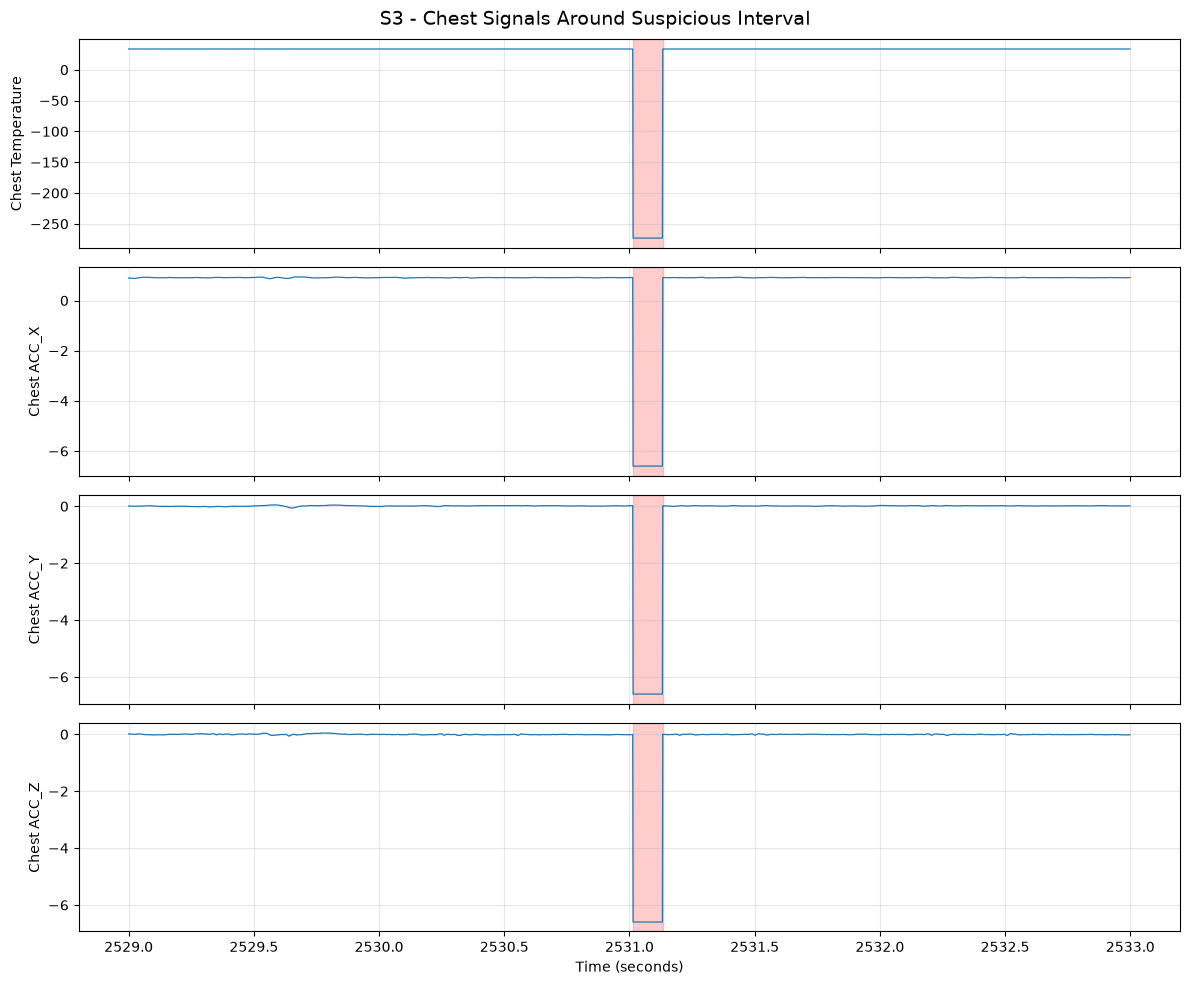

36

In [9]:
subject_id = "S3"
fs = 700

# Khoảng thời gian cần quan sát (giây)
start_time = 2529
end_time = 2533

# Đổi thời gian thành chỉ số mẫu
start_idx = int(start_time * fs)
end_idx = int(end_time * fs)

# Đọc dữ liệu S3
file_path = WESAD_ROOT / subject_id / f"{subject_id}.pkl"

with open(file_path, "rb") as f:
    data = pickle.load(f, encoding="latin1")

# Lấy dữ liệu trong khoảng thời gian cần quan sát
temp = data["signal"]["chest"]["Temp"][start_idx:end_idx, 0]
acc = data["signal"]["chest"]["ACC"][start_idx:end_idx, :]

# Tạo trục thời gian
time = np.arange(start_idx, end_idx) / fs

# Xác định những mẫu có giá trị đáng nghi đồng thời
temp_mask = np.isclose(
    temp, -273.15, atol=0.01, rtol=0
)

acc_mask = np.all(
    np.isclose(acc, -6.6, atol=0.001, rtol=0),
    axis=1
)

suspicious_mask = temp_mask & acc_mask
suspicious_indices = np.flatnonzero(suspicious_mask)

print("Số mẫu đáng nghi đồng thời:", len(suspicious_indices))

# Vẽ 4 biểu đồ
fig, axes = plt.subplots(
    4, 1,
    figsize=(12, 10),
    sharex=True
)

signals = [
    ("Chest Temperature", temp),
    ("Chest ACC_X", acc[:, 0]),
    ("Chest ACC_Y", acc[:, 1]),
    ("Chest ACC_Z", acc[:, 2])
]

for ax, (name, values) in zip(axes, signals):
    ax.plot(time, values, linewidth=0.9)
    ax.set_ylabel(name)
    ax.grid(True, alpha=0.3)

    # Đánh dấu khoảng thời gian đáng nghi
    if len(suspicious_indices) > 0:
        first_time = time[suspicious_indices[0]]
        last_time = time[suspicious_indices[-1]] + 1 / fs

        ax.axvspan(
            first_time,
            last_time,
            color="red",
            alpha=0.2
        )

axes[-1].set_xlabel("Time (seconds)")

fig.suptitle(
    "S3 - Chest Signals Around Suspicious Interval",
    fontsize=14
)

plt.tight_layout()
plt.show()

# Giải phóng dữ liệu
del data, temp, acc
gc.collect()


Các biểu đồ thể hiện tín hiệu nhiệt độ ngực và ba trục gia tốc của subject S3 trong khoảng 2529–2533 giây.

**Kết quả quan sát:**

- Tín hiệu `chest_Temp` đột ngột giảm xuống khoảng -273.15 rồi trở lại mức trước đó.
- Cả ba trục `chest_ACC_X`, `chest_ACC_Y` và `chest_ACC_Z` đồng thời giảm xuống khoảng -6.6.
- Những giá trị này xuất hiện trong cùng một đoạn gồm 83 mẫu liên tiếp, tương ứng khoảng 0.1186 giây ở tần số lấy mẫu 700 Hz.
- Trước và sau đoạn đáng nghi, các tín hiệu trở lại mức giá trị gần với trạng thái ban đầu.

**Đánh giá:**

Sự xuất hiện đồng thời của các giá trị cực trị trên bốn kênh, kết hợp với việc tín hiệu thay đổi đột ngột và phục hồi ngay sau đó, cho thấy đây có khả năng là một đoạn dữ liệu ghi nhận bất thường.

Giá trị nhiệt độ -273.15 không phù hợp với nhiệt độ cơ thể thực tế. Tuy nhiên, chưa thể xác định chính xác nguyên nhân của hiện tượng này chỉ từ biểu đồ.

**Kết luận:**

Đoạn dữ liệu tại khoảng 2531 giây của subject S3 cần được đánh dấu để xem xét trong giai đoạn tiền xử lý.

Hiện tại, dữ liệu được giữ nguyên. Chưa thực hiện xóa, thay thế hoặc nội suy các mẫu đáng nghi.

BVP lớn nhất theo trị tuyệt đối: 1789.0
Thời điểm cực trị (s): 4122.84375
Số mẫu của đoạn dài nhất: 37
Thời lượng đoạn dài nhất (s): 0.578125


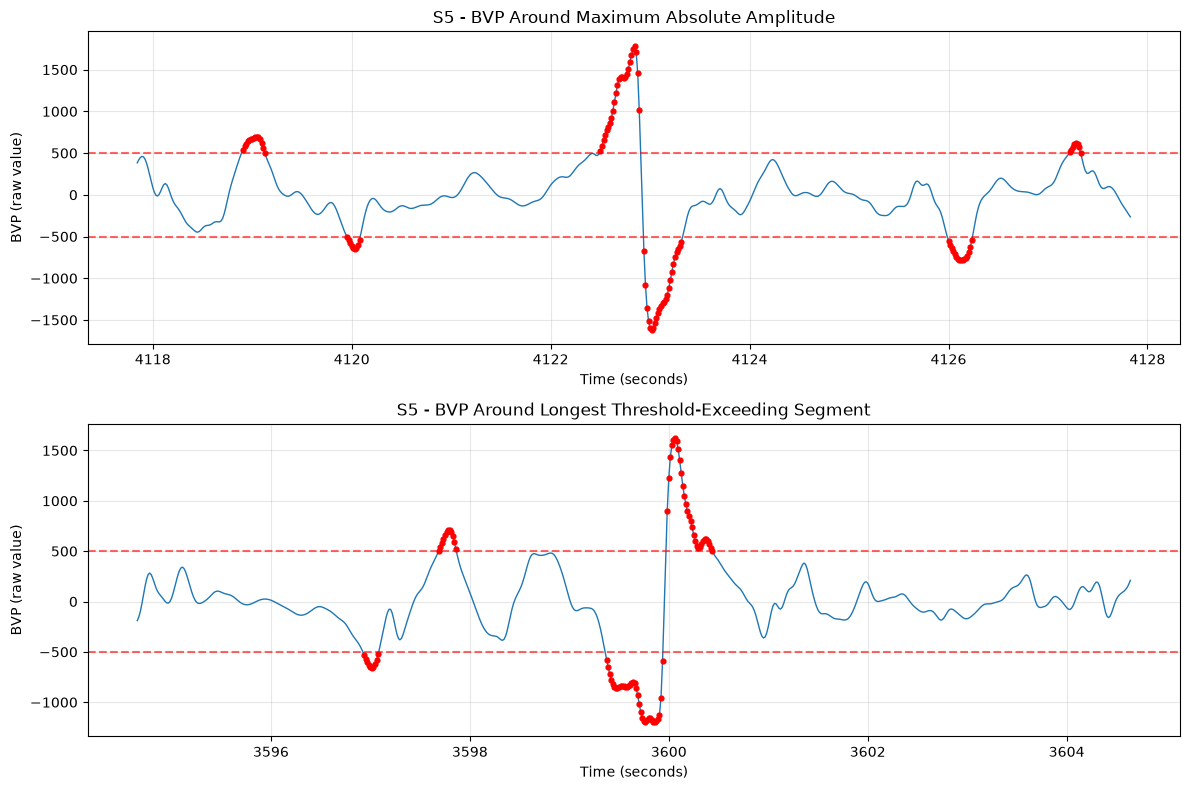

57

In [10]:
subject_id = "S5"
fs = 64
threshold = 500

file_path = WESAD_ROOT / subject_id / f"{subject_id}.pkl"

with open(file_path, "rb") as f:
    data = pickle.load(f, encoding="latin1")

# Lấy tín hiệu BVP
bvp = data["signal"]["wrist"]["BVP"][:, 0]

# 1. Vị trí có biên độ tuyệt đối lớn nhất
peak_idx = np.argmax(np.abs(bvp))

# 2. Tìm các đoạn liên tiếp có |BVP| > 500
mask = np.abs(bvp) > threshold
indices = np.flatnonzero(mask)

# Tìm vị trí bắt đầu và kết thúc từng đoạn
boundaries = np.where(np.diff(indices) > 1)[0]

starts = indices[np.r_[0, boundaries + 1]]
ends = indices[np.r_[boundaries, len(indices) - 1]]

# Độ dài từng đoạn
lengths = ends - starts + 1

# Chọn đoạn dài nhất
longest_idx = np.argmax(lengths)

longest_start = starts[longest_idx]
longest_end = ends[longest_idx]

longest_center = (longest_start + longest_end) // 2

print("BVP lớn nhất theo trị tuyệt đối:", bvp[peak_idx])
print("Thời điểm cực trị (s):", peak_idx / fs)
print("Số mẫu của đoạn dài nhất:", lengths[longest_idx])
print("Thời lượng đoạn dài nhất (s):",
      lengths[longest_idx] / fs)


# Hàm vẽ tín hiệu quanh một vị trí
def plot_bvp_segment(ax, center_idx, title):
    radius = 5 * fs

    start = max(0, center_idx - radius)
    end = min(len(bvp), center_idx + radius)

    x = bvp[start:end]
    time = np.arange(start, end) / fs

    # Vẽ tín hiệu gốc
    ax.plot(time, x, linewidth=1)

    # Đường ngưỡng tham chiếu
    ax.axhline(500, color="red", linestyle="--", alpha=0.6)
    ax.axhline(-500, color="red", linestyle="--", alpha=0.6)

    # Đánh dấu các mẫu vượt ngưỡng
    exceed = np.abs(x) > threshold

    ax.scatter(
        time[exceed],
        x[exceed],
        color="red",
        s=12,
        zorder=3
    )

    ax.set_title(title)
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("BVP (raw value)")
    ax.grid(True, alpha=0.3)


# Vẽ hai biểu đồ
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_bvp_segment(
    axes[0],
    peak_idx,
    "S5 - BVP Around Maximum Absolute Amplitude"
)

plot_bvp_segment(
    axes[1],
    longest_center,
    "S5 - BVP Around Longest Threshold-Exceeding Segment"
)

plt.tight_layout()
plt.show()

# Giải phóng bộ nhớ
del data, bvp
gc.collect()


Tiến hành trực quan hóa tín hiệu `wrist_BVP` của subject S5 tại hai khu vực: vùng chứa giá trị có biên độ tuyệt đối lớn nhất và vùng chứa chuỗi mẫu vượt ngưỡng liên tiếp dài nhất.

**1. Vùng có biên độ tuyệt đối lớn nhất**

- Giá trị BVP có độ lớn tuyệt đối lớn nhất là 1789.0, xuất hiện tại thời điểm 4122.84375 giây.
- Tín hiệu tăng mạnh lên biên độ dương lớn, sau đó chuyển nhanh xuống vùng biên độ âm lớn.
- Sự thay đổi đột ngột về biên độ cho thấy đây là khu vực cần tiếp tục đánh giá chất lượng tín hiệu.

**2. Vùng có chuỗi mẫu vượt ngưỡng dài nhất**

- Chuỗi liên tiếp dài nhất có 37 mẫu thỏa điều kiện $|BVP| > 500$.
- Với tần số lấy mẫu 64 Hz, thời lượng tương ứng là:

$$
T = \frac{37}{64} = 0.578125 \text{ giây}
$$

- Biểu đồ cho thấy tín hiệu có biến động biên độ mạnh tại khu vực khoảng 3600 giây.
- Các mẫu vượt ngưỡng không chỉ xuất hiện tại một thời điểm mà phân bố thành nhiều đoạn khác nhau trong bản ghi.

**3. Đánh giá**

Các biểu đồ cho thấy tín hiệu BVP của S5 xuất hiện những đoạn biến động biên độ mạnh, có khả năng liên quan đến nhiễu hoặc các yếu tố ảnh hưởng đến quá trình đo.

Tuy nhiên, biên độ lớn không đủ để kết luận tín hiệu bị lỗi. Ngưỡng $|BVP| > 500$ chỉ được sử dụng nhằm khảo sát và xác định những đoạn cần kiểm tra thêm.

**Kết luận**

Tín hiệu BVP của S5 chứa những đoạn biến động đáng chú ý về biên độ và hình dạng sóng. Cần xem xét thêm đặc điểm tín hiệu trước khi xác định phương pháp xử lý phù hợp.

Trong giai đoạn EDA, dữ liệu gốc được giữ nguyên, chưa thực hiện loại bỏ, thay thế hoặc hiệu chỉnh các mẫu tín hiệu.

In [11]:
label_names = {
    0: "Undefined",
    1: "Baseline",
    2: "Stress",
    3: "Amusement",
    4: "Meditation",
    5: "Ignore_5",
    6: "Ignore_6",
    7: "Ignore_7"
}

label_rows = []

for subject_id in SUBJECT_IDS:
    file_path = WESAD_ROOT / subject_id / f"{subject_id}.pkl"

    with open(file_path, "rb") as f:
        data = pickle.load(f, encoding="latin1")

    labels = data["label"]

    # Đếm số mẫu của từng nhãn
    unique_labels, counts = np.unique(
        labels, return_counts=True
    )

    label_counts = dict(zip(unique_labels, counts))

    row = {"Subject": subject_id}

    for label_id, label_name in label_names.items():
        row[label_name] = int(label_counts.get(label_id, 0))

    label_rows.append(row)

    print(f"[OK] Đã thống kê nhãn {subject_id}")

    del data, labels
    gc.collect()


# Bảng số lượng mẫu nhãn của từng subject
df_label_counts = pd.DataFrame(label_rows)
df_label_counts = df_label_counts.set_index("Subject")

print("SỐ LƯỢNG MẪU THEO NHÃN - 15 SUBJECT")
display(df_label_counts)


# Bảng tỷ lệ nhãn (%) của từng subject
df_label_percent = (
    df_label_counts
    .div(df_label_counts.sum(axis=1), axis=0)
    * 100
)

print("TỶ LỆ PHÂN PHỐI NHÃN (%) - 15 SUBJECT")
display(df_label_percent.round(2))


# Tổng hợp số mẫu và tỷ lệ nhãn của toàn bộ dataset
total_counts = df_label_counts.sum(axis=0)

df_label_overall = pd.DataFrame({
    "Count": total_counts,
    "Percentage (%)": (
        total_counts / total_counts.sum() * 100
    )
})

print("PHÂN PHỐI NHÃN TỔNG THỂ - WESAD")
display(df_label_overall.round(2))


[OK] Đã thống kê nhãn S2
[OK] Đã thống kê nhãn S3
[OK] Đã thống kê nhãn S4
[OK] Đã thống kê nhãn S5
[OK] Đã thống kê nhãn S6
[OK] Đã thống kê nhãn S7
[OK] Đã thống kê nhãn S8
[OK] Đã thống kê nhãn S9
[OK] Đã thống kê nhãn S10
[OK] Đã thống kê nhãn S11
[OK] Đã thống kê nhãn S13
[OK] Đã thống kê nhãn S14
[OK] Đã thống kê nhãn S15
[OK] Đã thống kê nhãn S16
[OK] Đã thống kê nhãn S17
SỐ LƯỢNG MẪU THEO NHÃN - 15 SUBJECT


,Undefined,Baseline,Stress,Amusement,Meditation,Ignore_5,Ignore_6,Ignore_7
Subject,,,,,,,,
S2,2142701,800800,430500,253400,537599,0,45500,44800
S3,2345699,798000,448000,262500,546001,51100,46900,46900
S4,2314199,810601,444500,260400,563500,35699,30800,36401
S5,2142700,838600,451500,261800,555800,50401,30799,49000
S6,2733499,826000,455000,260400,550900,40600,35001,48300
S7,1472098,830200,448000,260401,553001,35000,30799,37101
S8,1616300,818300,469000,258999,557200,34300,35701,36400
S9,1435700,826000,451500,260400,555100,42000,43400,42000
S10,1589000,826000,507500,260400,557200,35700,31500,39900


TỶ LỆ PHÂN PHỐI NHÃN (%) - 15 SUBJECT


,Undefined,Baseline,Stress,Amusement,Meditation,Ignore_5,Ignore_6,Ignore_7
Subject,,,,,,,,
S2,50.35,18.82,10.12,5.95,12.63,0.00,1.07,1.05
S3,51.61,17.56,9.86,5.78,12.01,1.12,1.03,1.03
S4,51.47,18.03,9.89,5.79,12.53,0.79,0.69,0.81
S5,48.91,19.14,10.31,5.98,12.69,1.15,0.70,1.12
S6,55.23,16.69,9.19,5.26,11.13,0.82,0.71,0.98
S7,40.15,22.64,12.22,7.10,15.08,0.95,0.84,1.01
S8,42.24,21.39,12.26,6.77,14.56,0.90,0.93,0.95
S9,39.27,22.59,12.35,7.12,15.18,1.15,1.19,1.15
S10,41.30,21.47,13.19,6.77,14.48,0.93,0.82,1.04


PHÂN PHỐI NHÃN TỔNG THỂ - WESAD


,Count,Percentage (%)
Undefined,27654897,45.48
Baseline,12327702,20.27
Stress,6976201,11.47
Amusement,3902501,6.42
Meditation,8264199,13.59
Ignore_5,552300,0.91
Ignore_6,552998,0.91
Ignore_7,576802,0.95


Phân tích phân phối nhãn được thực hiện trên toàn bộ 15 subject với tổng cộng **60.807.600 mẫu nhãn** ở tần số lấy mẫu 700 Hz.

**1. Phân phối nhãn gốc**

- Nhãn `Undefined (0)` chiếm tỷ lệ lớn nhất (45.48%).
- Nhãn `Baseline (1)` chiếm 20.27%.
- Nhãn `Stress (2)` chiếm 11.47%.
- Nhãn `Amusement (3)` chiếm 6.42%.
- Nhãn `Meditation (4)` chiếm 13.59%.
- Các nhãn 5, 6 và 7 chiếm tổng cộng khoảng 2.77%.

Nhãn `Undefined (0)` không đồng nghĩa với trạng thái Baseline, do đó không được xem là nhãn 0 của bài toán phân loại ba lớp.

**2. Phân phối của ba lớp mục tiêu**

Đối với bài toán nhận diện ba trạng thái Baseline, Stress và Amusement, tổng số mẫu mang nhãn 1, 2 hoặc 3 là **23.206.404 mẫu**, tương đương khoảng 38.16% số mẫu nhãn gốc.

Khi chỉ xét ba lớp này:

| Trạng thái | Số mẫu | Tỷ lệ |
|---|---:|---:|
| Baseline | 12.327.702 | 53.12% |
| Stress | 6.976.201 | 30.06% |
| Amusement | 3.902.501 | 16.82% |

Số mẫu Baseline lớn hơn khoảng 3.16 lần so với Amusement, cho thấy sự mất cân bằng giữa các lớp mục tiêu.

**3. Sự khác biệt giữa các subject**

Tỷ lệ nhãn `Undefined` thay đổi đáng kể giữa các subject, từ khoảng 39.27% ở S9 đến 55.23% ở S6.

Trong khi đó, số mẫu thuộc các trạng thái mục tiêu tương đối gần nhau hơn giữa các subject.

**Kết luận**

Dữ liệu WESAD có sự mất cân bằng về số lượng mẫu giữa các trạng thái, đặc biệt khi xét ba lớp Baseline, Stress và Amusement.

Kết quả này cần được lưu ý khi lựa chọn phương pháp đánh giá mô hình. Các chỉ số như Macro-F1 và Balanced Accuracy có thể giúp đánh giá hiệu suất giữa các lớp mà không chỉ dựa vào Accuracy tổng thể.

Tuy nhiên, phân phối hiện tại được tính trên các mẫu nhãn gốc ở 700 Hz. Phân phối của các cửa sổ huấn luyện có thể thay đổi sau các bước tiền xử lý.

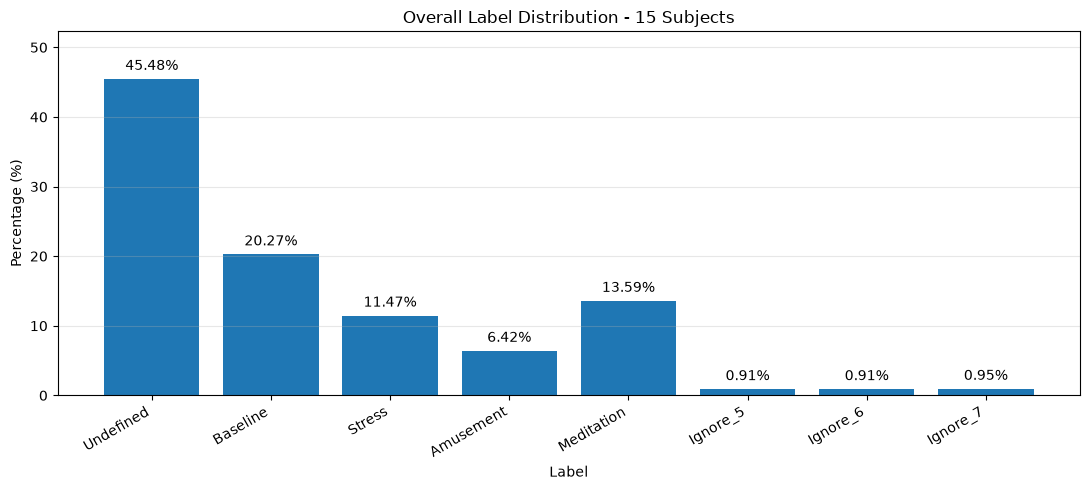

In [13]:
fig, ax = plt.subplots(figsize=(11, 5))

percentages = df_label_overall["Percentage (%)"]

bars = ax.bar(
    percentages.index,
    percentages.values
)

# Hiển thị tỷ lệ phía trên mỗi cột
for bar, value in zip(bars, percentages):
    ax.annotate(
        f"{value:.2f}%",
        (
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points"
    )

ax.set_title("Overall Label Distribution - 15 Subjects")
ax.set_xlabel("Label")
ax.set_ylabel("Percentage (%)")
ax.set_ylim(0, percentages.max() * 1.15)
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


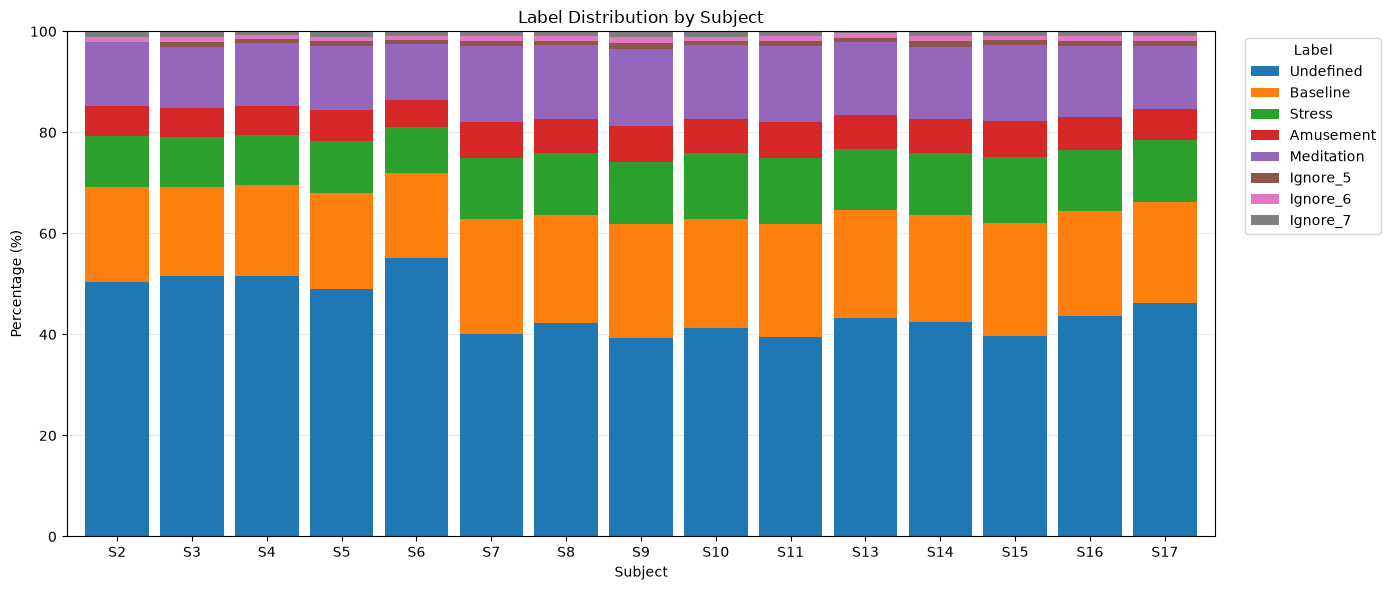

In [12]:
ax = df_label_percent.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 6),
    width=0.85
)

ax.set_title("Label Distribution by Subject")
ax.set_xlabel("Subject")
ax.set_ylabel("Percentage (%)")
ax.set_ylim(0, 100)

ax.legend(
    title="Label",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Hai biểu đồ thể hiện phân phối nhãn tổng thể và tỷ lệ nhãn của từng subject trong bộ dữ liệu WESAD.

**1. Phân phối nhãn tổng thể**

- Nhãn `Undefined (0)` chiếm tỷ lệ cao nhất (45.48%).
- Trong các trạng thái chính, `Baseline` chiếm 20.27%, `Meditation` chiếm 13.59%, `Stress` chiếm 11.47% và `Amusement` chiếm 6.42%.
- Các nhãn Ignore (5, 6, 7) có tỷ lệ thấp, mỗi nhãn chiếm khoảng 1%.

Biểu đồ cho thấy phân phối nhãn không đồng đều. Trong ba lớp mục tiêu Baseline, Stress và Amusement, Baseline có nhiều mẫu nhất và Amusement có ít mẫu nhất.

**2. Phân phối nhãn giữa các subject**

- Tỷ lệ `Undefined` khác nhau đáng kể giữa các subject.
- Subject S6 có tỷ lệ Undefined cao nhất (55.23%), trong khi S9 có tỷ lệ thấp nhất (39.27%).
- Phân phối của các trạng thái Baseline, Stress và Amusement tương đối giống nhau giữa các subject, mặc dù vẫn có sự chênh lệch về tỷ lệ.

**3. Đánh giá**

Các biểu đồ cho thấy sự mất cân bằng về số lượng mẫu giữa các trạng thái trong dữ liệu gốc.

Đối với bài toán phân loại ba lớp Baseline, Stress và Amusement, sự mất cân bằng cần được xem xét khi lựa chọn phương pháp đánh giá mô hình.

Tuy nhiên, đây là phân phối nhãn gốc ở tần số 700 Hz. Số lượng và tỷ lệ các lớp có thể thay đổi sau khi lọc nhãn và chia dữ liệu thành các cửa sổ thời gian.

**Kết luận**

Phân phối nhãn WESAD không đồng đều, đồng thời tồn tại sự khác biệt giữa các subject. Kết quả này cung cấp cơ sở để phân tích sự mất cân bằng lớp và xây dựng phương pháp đánh giá phù hợp trong các giai đoạn tiếp theo.

TỔNG HỢP SỐ ĐOẠN NHÃN LIÊN TIẾP CỦA 15 SUBJECT


,Subject,Total_duration_min,Num_segments
0,S2,101.32,15
1,S3,108.22,17
2,S4,107.05,17
3,S5,104.30,17
4,S6,117.85,17
5,S7,87.30,17
6,S8,91.10,17
7,S9,87.05,17
8,S10,91.60,17
9,S11,87.22,17


XEM THỬ 20 DÒNG ĐẦU CỦA BẢNG SEGMENT


,Subject,Segment,Label,State,Start_sec,End_sec,Duration_sec,Start_min,End_min,Duration_min
0,S2,1,0,Undefined,0.00,306.55,306.55,0.00,5.11,5.11
1,S2,2,1,Baseline,306.55,1450.55,1144.00,5.11,24.18,19.07
2,S2,3,0,Undefined,1450.55,2273.55,823.00,24.18,37.89,13.72
3,S2,4,2,Stress,2273.55,2888.55,615.00,37.89,48.14,10.25
4,S2,5,0,Undefined,2888.55,3160.55,272.00,48.14,52.68,4.53
5,S2,6,6,Ignore_6,3160.55,3225.55,65.00,52.68,53.76,1.08
6,S2,7,0,Undefined,3225.55,4097.55,872.00,53.76,68.29,14.53
7,S2,8,4,Meditation,4097.55,4488.55,391.00,68.29,74.81,6.52
8,S2,9,0,Undefined,4488.55,4763.55,275.00,74.81,79.39,4.58
9,S2,10,3,Amusement,4763.55,5125.55,362.00,79.39,85.43,6.03


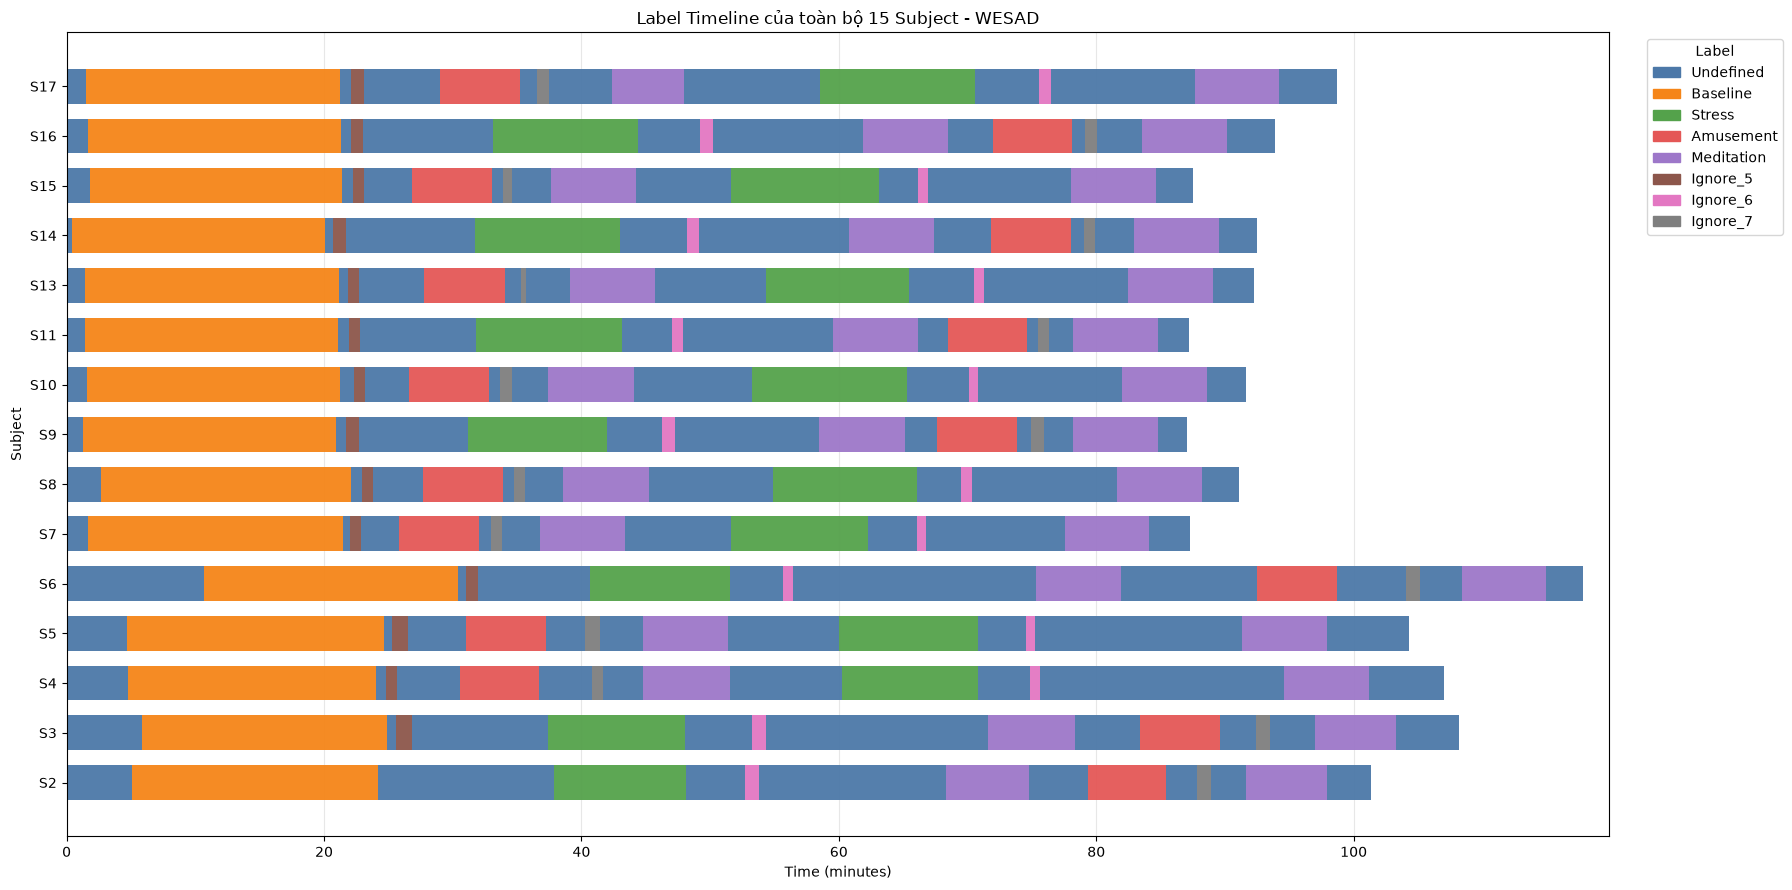

In [14]:
import pickle
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Danh sách 15 subject của WESAD
subject_ids = [
    "S2", "S3", "S4", "S5", "S6",
    "S7", "S8", "S9", "S10", "S11",
    "S13", "S14", "S15", "S16", "S17"
]

# Tần số lấy mẫu của label
fs_label = 700

# Tên nhãn
label_names = {
    0: "Undefined",
    1: "Baseline",
    2: "Stress",
    3: "Amusement",
    4: "Meditation",
    5: "Ignore_5",
    6: "Ignore_6",
    7: "Ignore_7"
}

# Màu cho từng nhãn
label_colors = {
    0: "#4C78A8",  # xanh dương
    1: "#F58518",  # cam
    2: "#54A24B",  # xanh lá
    3: "#E45756",  # đỏ
    4: "#9D77C9",  # tím
    5: "#8C564B",  # nâu
    6: "#E377C2",  # hồng
    7: "#7F7F7F"   # xám
}

all_segments = []
duration_summary = []

for subject_id in subject_ids:
    file_path = WESAD_ROOT / subject_id / f"{subject_id}.pkl"
    
    with open(file_path, "rb") as f:
        data = pickle.load(f, encoding="latin1")
    
    labels = data["label"]

    # Tìm vị trí đổi nhãn
    change_points = np.flatnonzero(labels[1:] != labels[:-1]) + 1
    boundaries = np.r_[0, change_points, len(labels)]
    segment_labels = labels[boundaries[:-1]]

    # Tạo dataframe các đoạn liên tiếp
    df_segments = pd.DataFrame({
        "Subject": subject_id,
        "Segment": np.arange(1, len(segment_labels) + 1),
        "Label": segment_labels,
        "State": [label_names.get(int(x), f"Label_{x}") for x in segment_labels],
        "Start_sec": boundaries[:-1] / fs_label,
        "End_sec": boundaries[1:] / fs_label,
        "Duration_sec": np.diff(boundaries) / fs_label
    })
    
    df_segments["Start_min"] = df_segments["Start_sec"] / 60
    df_segments["End_min"] = df_segments["End_sec"] / 60
    df_segments["Duration_min"] = df_segments["Duration_sec"] / 60

    all_segments.append(df_segments)

    # Tổng thời lượng subject
    total_duration_min = len(labels) / fs_label / 60
    duration_summary.append({
        "Subject": subject_id,
        "Total_duration_min": total_duration_min,
        "Num_segments": len(df_segments)
    })

    del data, labels
    gc.collect()

# Ghép toàn bộ segment
df_all_segments = pd.concat(all_segments, ignore_index=True)
df_duration_summary = pd.DataFrame(duration_summary)

print("TỔNG HỢP SỐ ĐOẠN NHÃN LIÊN TIẾP CỦA 15 SUBJECT")
display(df_duration_summary.round(2))

print("XEM THỬ 20 DÒNG ĐẦU CỦA BẢNG SEGMENT")
display(df_all_segments.head(20).round(2))

# -----------------------------
# VẼ TIMELINE CHO 15 SUBJECT
# -----------------------------
fig, ax = plt.subplots(figsize=(18, 9))

row_height = 0.7
y_positions = np.arange(len(subject_ids))

for i, subject_id in enumerate(subject_ids):
    temp = df_all_segments[df_all_segments["Subject"] == subject_id]
    
    for _, row in temp.iterrows():
        ax.broken_barh(
            [(row["Start_min"], row["Duration_min"])],
            (i - row_height / 2, row_height),
            facecolors=label_colors[int(row["Label"])],
            edgecolors="none",
            alpha=0.95
        )

ax.set_yticks(y_positions)
ax.set_yticklabels(subject_ids)
ax.set_xlabel("Time (minutes)")
ax.set_ylabel("Subject")
ax.set_title("Label Timeline của toàn bộ 15 Subject - WESAD")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

# Giới hạn trục x theo subject dài nhất
max_duration = df_duration_summary["Total_duration_min"].max()
ax.set_xlim(0, max_duration + 2)

# Tạo legend
legend_patches = [
    mpatches.Patch(color=label_colors[k], label=label_names[k])
    for k in sorted(label_names.keys())
]
ax.legend(
    handles=legend_patches,
    title="Label",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

**1. Số lượng đoạn nhãn và thời lượng ghi nhận**

- Subject S2 có 15 đoạn nhãn liên tiếp.
- 14 subject còn lại đều có 17 đoạn nhãn liên tiếp.
- Subject S6 có thời lượng ghi nhận dài nhất (117.85 phút).
- Subject S9 có thời lượng ghi nhận ngắn nhất (87.05 phút).

Số đoạn nhãn (`Num_segments`) thể hiện số khoảng thời gian liên tiếp có cùng giá trị nhãn, không phải số loại nhãn khác nhau.

**2. Trình tự xuất hiện các trạng thái**

- Các trạng thái xuất hiện thành từng đoạn liên tiếp có thời điểm bắt đầu và kết thúc xác định.
- Baseline thường xuất hiện ở giai đoạn đầu bản ghi.
- Thứ tự xuất hiện của Stress và Amusement không hoàn toàn giống nhau giữa các subject.
- Undefined chiếm thời lượng đáng kể và thường xuất hiện xen giữa các trạng thái khác.
- Một số trạng thái như Meditation có thể xuất hiện nhiều lần trong cùng một bản ghi.

**3. Ví dụ từ subject S2**

- Baseline kéo dài 1144 giây (19.07 phút).
- Stress kéo dài 615 giây (10.25 phút).
- Amusement kéo dài 362 giây (6.03 phút).
- Meditation xuất hiện trong hai đoạn riêng biệt, lần lượt kéo dài 391 giây và 377 giây.

Các trạng thái mục tiêu không nhất thiết xuất hiện liên tiếp mà có thể được ngăn cách bởi những khoảng Undefined hoặc các nhãn khác.

**4. Ý nghĩa đối với bài toán nhận diện stress**

Kết quả cho thấy cấu trúc thời gian của nhãn là thông tin quan trọng khi chuẩn bị dữ liệu cho mô hình học sâu.

Trong giai đoạn tiền xử lý, cần xác định cách tạo cửa sổ theo thời gian và cách xử lý các cửa sổ nằm gần ranh giới chuyển đổi giữa các trạng thái.

Đặc biệt, cần tránh gán nhãn không chính xác cho những cửa sổ chứa đồng thời nhiều trạng thái khác nhau.

**Kết luận**

Timeline của 15 subject cho thấy WESAD có cấu trúc nhãn theo từng đoạn thời gian rõ ràng, nhưng khác biệt về thời lượng và trình tự xuất hiện giữa các cá nhân.

Kết quả này cung cấp cơ sở để lựa chọn phương pháp phân đoạn và gán nhãn cửa sổ trong giai đoạn tiền xử lý.

In [15]:
rng = np.random.default_rng(42)
sample_size = 5000

# Lưu các mẫu theo từng kênh và subject
sampled_signals = {}

for subject_id in SUBJECT_IDS:
    file_path = WESAD_ROOT / subject_id / f"{subject_id}.pkl"

    with open(file_path, "rb") as f:
        data = pickle.load(f, encoding="latin1")

    for device, signals in data["signal"].items():
        for signal_name, values in signals.items():

            # Chọn ngẫu nhiên các hàng, không lặp lại
            n = min(sample_size, values.shape[0])

            indices = rng.choice(
                values.shape[0],
                size=n,
                replace=False
            )

            # ACC có 3 kênh, tín hiệu khác có 1 kênh
            for i in range(values.shape[1]):

                if signal_name == "ACC":
                    channel = f"{device}_ACC_{'XYZ'[i]}"
                else:
                    channel = f"{device}_{signal_name}"

                if channel not in sampled_signals:
                    sampled_signals[channel] = {}

                x = values[indices, i]

                # Chỉ giữ giá trị hữu hạn để vẽ
                sampled_signals[channel][subject_id] = x[
                    np.isfinite(x)
                ]

    print(f"[OK] Đã lấy mẫu {subject_id}")

    del data
    gc.collect()

print("\nSố kênh:", len(sampled_signals))
print("Số subject:", len(SUBJECT_IDS))


[OK] Đã lấy mẫu S2
[OK] Đã lấy mẫu S3
[OK] Đã lấy mẫu S4
[OK] Đã lấy mẫu S5
[OK] Đã lấy mẫu S6
[OK] Đã lấy mẫu S7
[OK] Đã lấy mẫu S8
[OK] Đã lấy mẫu S9
[OK] Đã lấy mẫu S10
[OK] Đã lấy mẫu S11
[OK] Đã lấy mẫu S13
[OK] Đã lấy mẫu S14
[OK] Đã lấy mẫu S15
[OK] Đã lấy mẫu S16
[OK] Đã lấy mẫu S17

Số kênh: 14
Số subject: 15


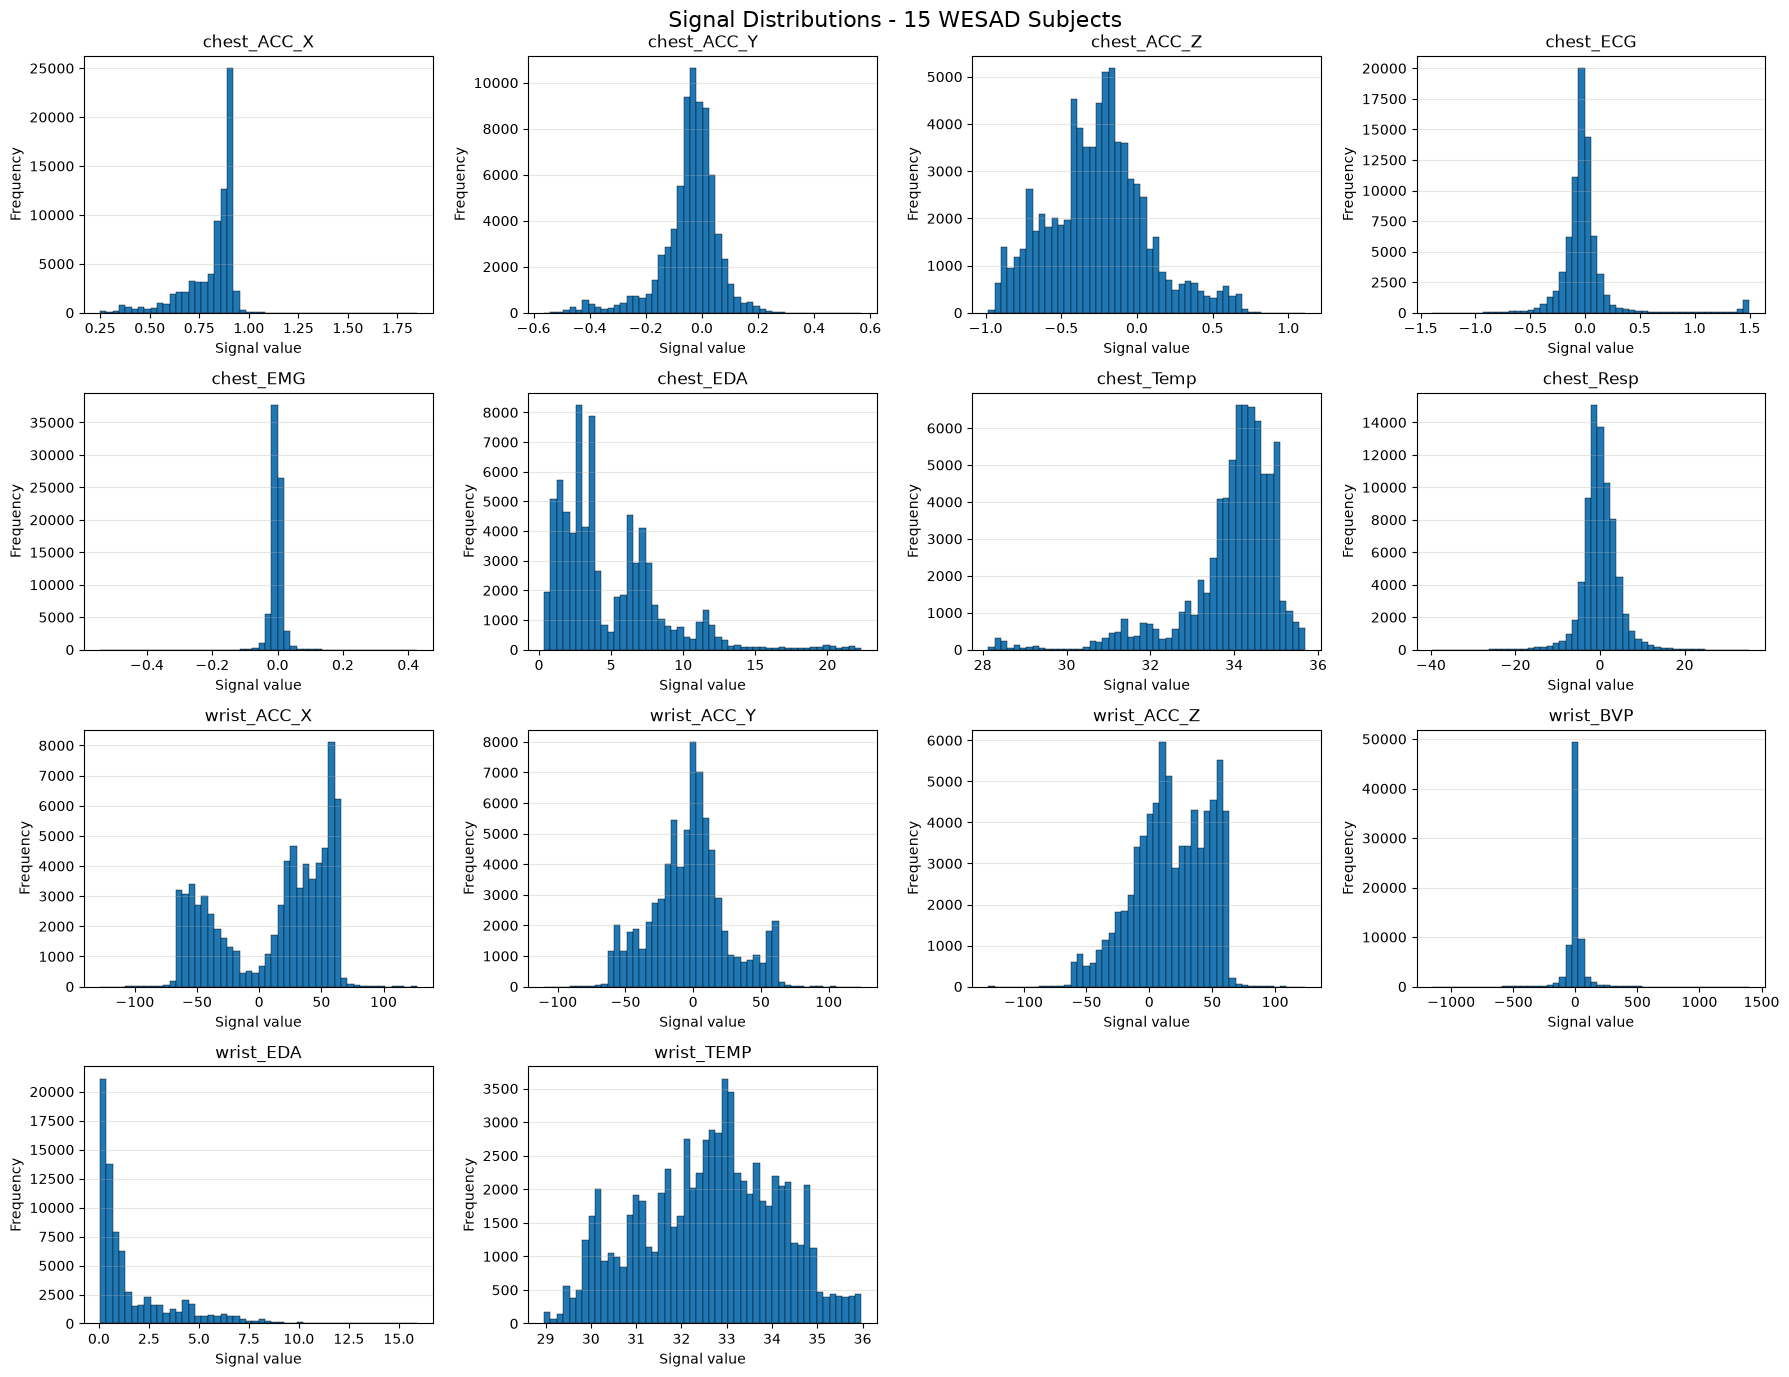

In [16]:
channels = list(sampled_signals.keys())

fig, axes = plt.subplots(
    4, 4,
    figsize=(18, 14)
)

axes = axes.flatten()

for i, channel in enumerate(channels):
    ax = axes[i]

    # Gộp mẫu của 15 subject cho cùng một kênh
    values = np.concatenate([
        sampled_signals[channel][subject]
        for subject in SUBJECT_IDS
    ])

    ax.hist(
        values,
        bins=50,
        edgecolor="black",
        linewidth=0.3
    )

    ax.set_title(channel)
    ax.set_xlabel("Signal value")
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", alpha=0.3)

# Ẩn các ô biểu đồ không sử dụng
for j in range(len(channels), len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    "Signal Distributions - 15 WESAD Subjects",
    fontsize=16
)

plt.tight_layout()
plt.show()


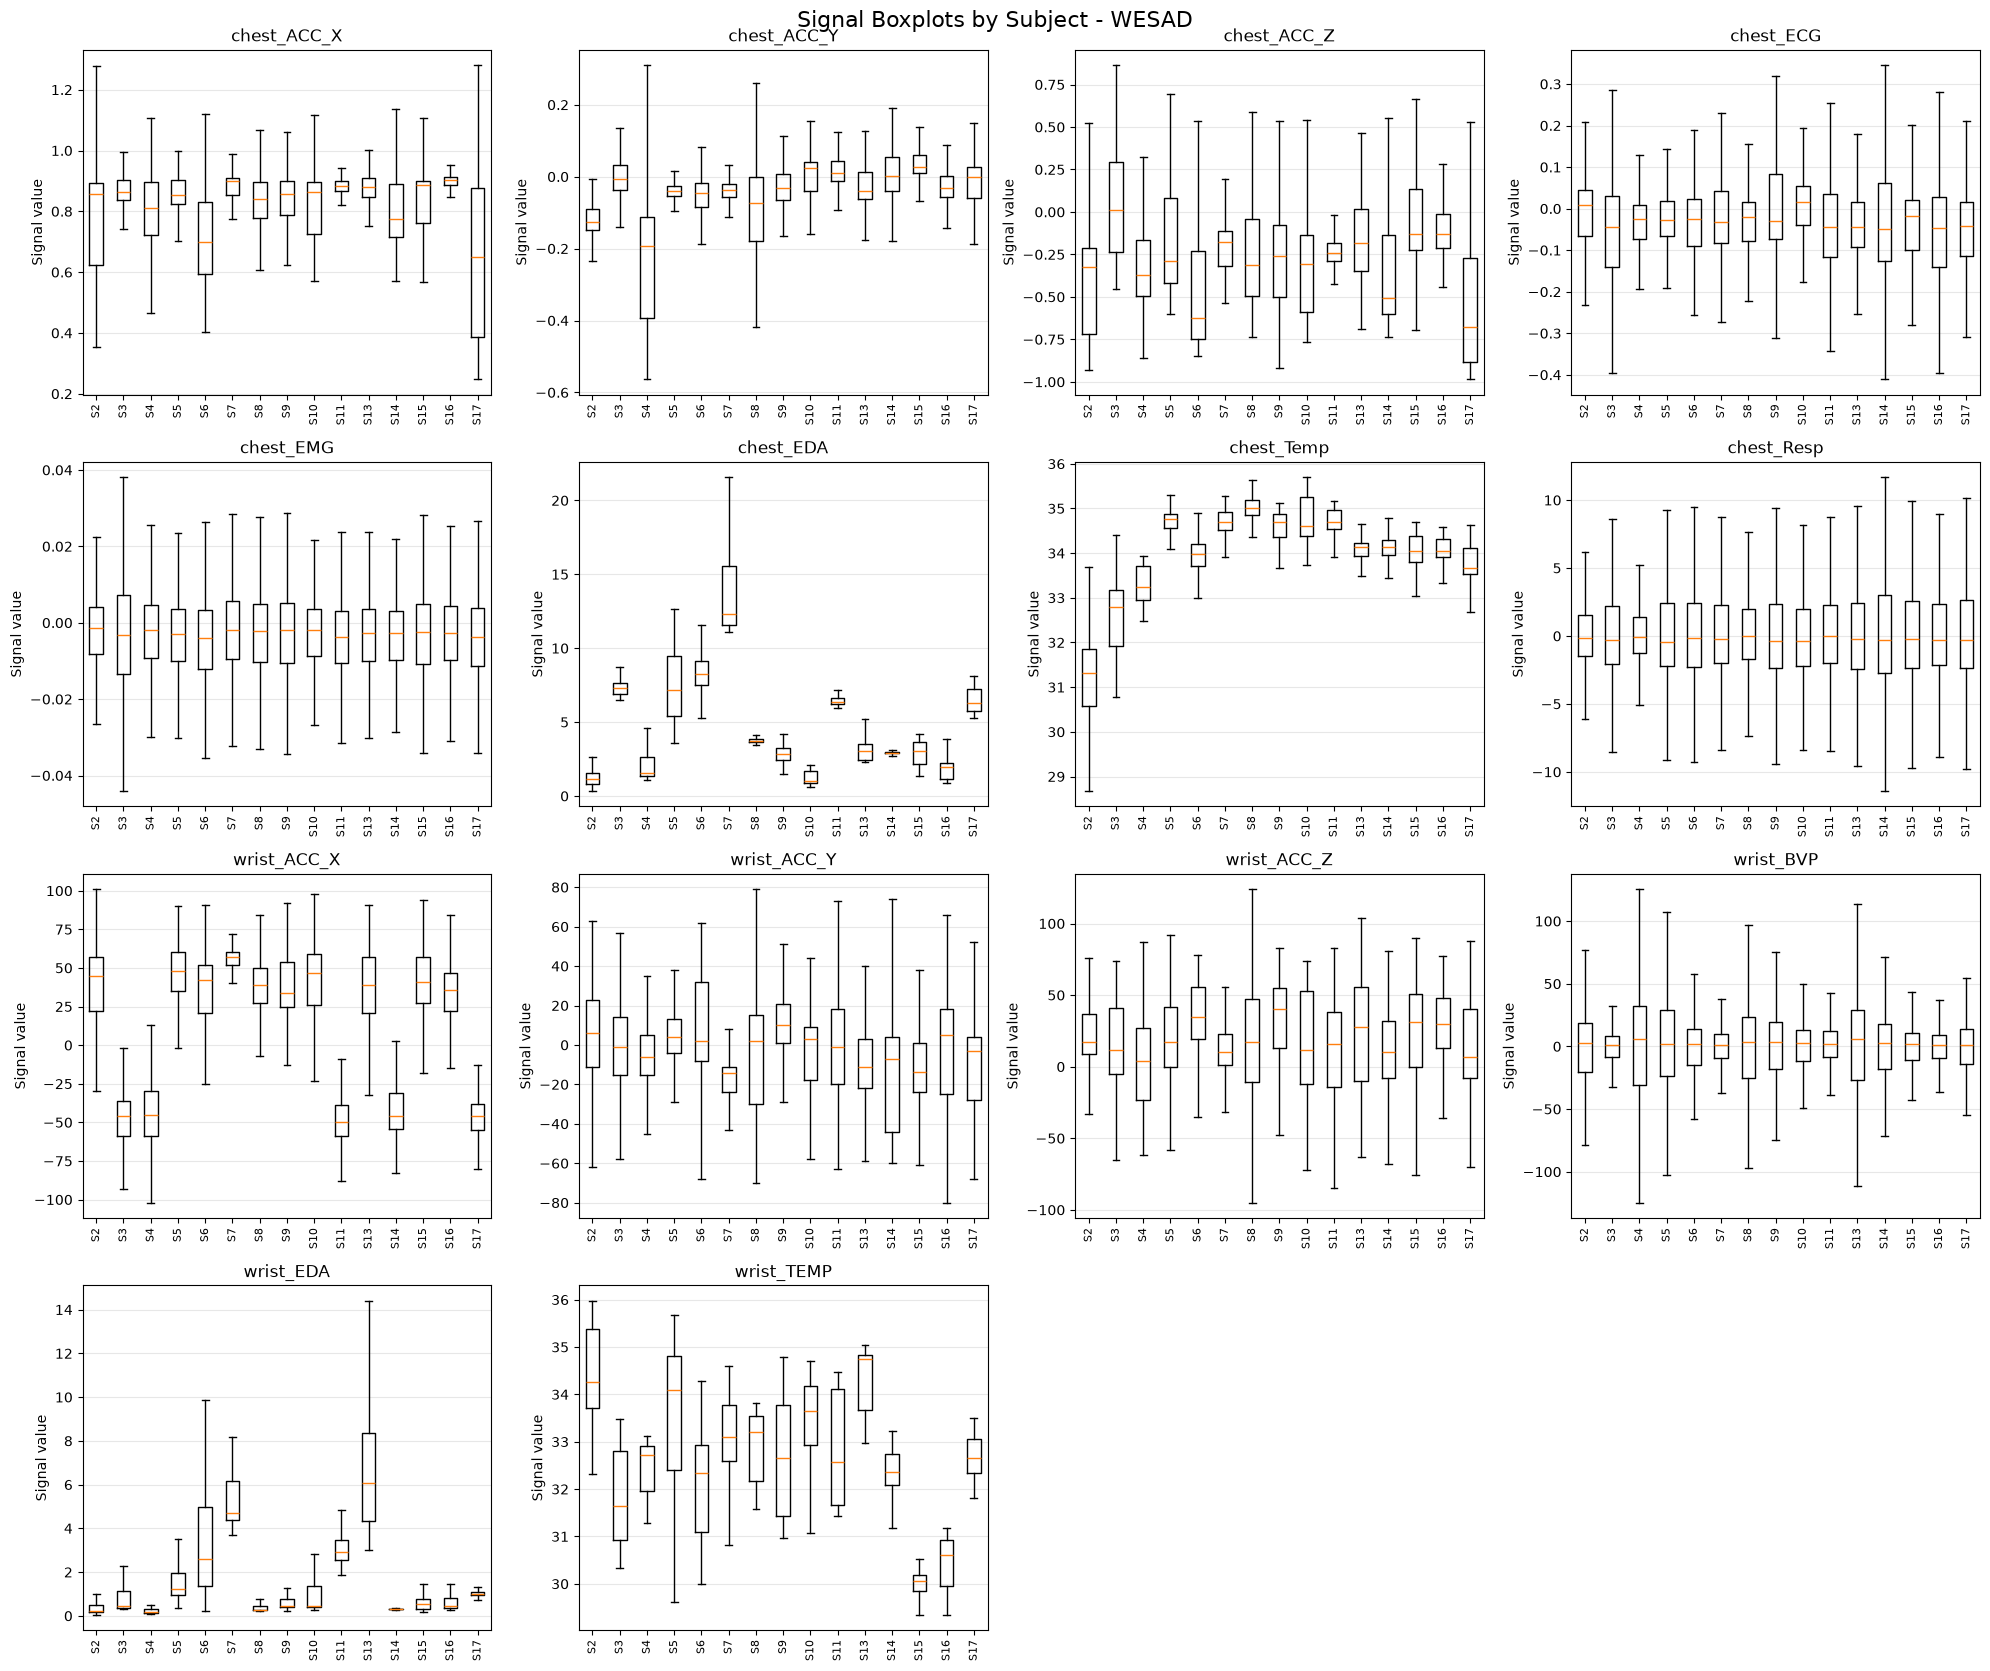

In [17]:
fig, axes = plt.subplots(
    4, 4,
    figsize=(20, 17)
)

axes = axes.flatten()

for i, channel in enumerate(channels):
    ax = axes[i]

    # Dữ liệu của từng subject cho kênh hiện tại
    data_to_plot = [
        sampled_signals[channel][subject]
        for subject in SUBJECT_IDS
    ]

    ax.boxplot(
        data_to_plot,
        showfliers=False
    )

    ax.set_title(channel)
    ax.set_ylabel("Signal value")

    ax.set_xticks(range(1, len(SUBJECT_IDS) + 1))
    ax.set_xticklabels(
        SUBJECT_IDS,
        rotation=90,
        fontsize=8
    )

    ax.grid(axis="y", alpha=0.3)

# Ẩn các ô không sử dụng
for j in range(len(channels), len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    "Signal Boxplots by Subject - WESAD",
    fontsize=16
)

plt.tight_layout()
plt.show()


**1. Histogram — Phân phối giá trị**

- Các kênh gia tốc (ACC) có hình dạng phân phối khác nhau. Đặc biệt, ACC cổ tay xuất hiện nhiều vùng tập trung giá trị, có thể liên quan đến sự khác biệt về tư thế và hướng đặt cảm biến.
- ECG, EMG và BVP có nhiều giá trị tập trung gần mức 0, nhưng phạm vi dao động và hình dạng phân phối khác nhau.
- EDA ngực có phân phối nhiều đỉnh, trong khi EDA cổ tay thể hiện phân phối lệch phải với phần lớn giá trị tập trung ở vùng thấp.
- Các mẫu nhiệt độ ngực và cổ tay chủ yếu tập trung trong khoảng 29–36°C.
- Một số tín hiệu có đuôi phân phối kéo dài, cho thấy sự xuất hiện của các giá trị cực trị.

**2. Boxplot — So sánh giữa các subject**

- Vị trí trung vị (Median) và khoảng tứ phân vị (IQR) khác nhau giữa các subject.
- Các kênh ACC cổ tay có sự khác biệt đáng kể về vị trí trung tâm của phân phối.
- EDA ngực và cổ tay thể hiện sự chênh lệch rõ rệt giữa các cá nhân.
- Nhiệt độ ngực và cổ tay cũng có sự khác biệt về trung vị và độ phân tán giữa các subject.
- Một số tín hiệu như ECG, EMG và Resp có vị trí trung tâm tương đối gần nhau hơn giữa các subject, nhưng vẫn tồn tại sự khác biệt về độ phân tán.

**3. Hạn chế của trực quan hóa**

- Histogram và Boxplot được tạo từ dữ liệu lấy mẫu ngẫu nhiên, không phải toàn bộ dữ liệu gốc.
- Các giá trị bất thường hiếm gặp có thể không xuất hiện trong mẫu trực quan hóa.
- Boxplot sử dụng `showfliers=False` để ẩn các điểm nằm ngoài râu biểu đồ; thao tác này không xóa outlier khỏi dữ liệu.
- Histogram tổng hợp các mẫu từ 15 subject nên các đỉnh phân phối có thể chịu ảnh hưởng từ sự khác biệt giữa các cá nhân.

**Kết luận**

Các tín hiệu cảm biến WESAD có đặc điểm phân phối khác nhau, đồng thời tồn tại sự khác biệt về mức giá trị và độ phân tán giữa các subject.

Kết quả này cho thấy cần xem xét sự khác biệt giữa các cá nhân khi thiết kế quy trình tiền xử lý và đánh giá mô hình.

Tuy nhiên, chưa thể xác định phương pháp chuẩn hóa hoặc xử lý outlier phù hợp chỉ dựa trên các biểu đồ. Những quyết định này cần được kiểm chứng trong giai đoạn tiền xử lý và thực nghiệm.

# 3. Tiền xử lý dữ liệu

## 3.1. Xác định tín hiệu đầu vào và nhãn mục tiêu

Dựa trên kết quả khám phá dữ liệu, bài toán sử dụng toàn bộ 10 loại tín hiệu cảm biến thuộc hai thiết bị RespiBAN và Empatica E4, tương ứng 14 kênh dữ liệu.

**Tín hiệu đầu vào:**

- Chest: ACC (X, Y, Z), ECG, EMG, EDA, Temp, Resp.
- Wrist: ACC (X, Y, Z), BVP, EDA, TEMP.

**Nhãn mục tiêu:**

Bài toán được xây dựng dưới dạng phân loại ba trạng thái:

| Nhãn WESAD gốc | Trạng thái | Nhãn mô hình |
|---|---|---|
| 1 | Baseline | 0 |
| 2 | Stress | 1 |
| 3 | Amusement | 2 |

Các nhãn gốc 0, 4, 5, 6, 7 không thuộc ba lớp mục tiêu và sẽ không được sử dụng để tạo mẫu huấn luyện hợp lệ.

Việc mã hóa lại nhãn chỉ áp dụng trong quá trình chuẩn bị dữ liệu, không thay đổi mảng nhãn trong các file PKL gốc.

Ngoài ra, do các tín hiệu cảm biến có tần số lấy mẫu khác nhau, cần xác định phương pháp đồng bộ thời gian phù hợp trước khi kết hợp các kênh thành đầu vào thống nhất cho mô hình.

In [18]:
SIGNAL_CONFIG = {
    "chest": {
        "ACC": 700,
        "ECG": 700,
        "EMG": 700,
        "EDA": 700,
        "Temp": 700,
        "Resp": 700
    },
    "wrist": {
        "ACC": 32,
        "BVP": 64,
        "EDA": 4,
        "TEMP": 4
    }
}

# Ánh xạ nhãn gốc sang nhãn mô hình
LABEL_MAPPING = {
    1: 0,  # Baseline
    2: 1,  # Stress
    3: 2   # Amusement
}

TARGET_CLASSES = ["Baseline", "Stress", "Amusement"]

# Kiểm tra cấu hình
print("Số loại tín hiệu:",
      sum(len(signals) for signals in SIGNAL_CONFIG.values()))

print("Nhãn mục tiêu:", LABEL_MAPPING)
print("Tên các lớp:", TARGET_CLASSES)


Số loại tín hiệu: 10
Nhãn mục tiêu: {1: 0, 2: 1, 3: 2}
Tên các lớp: ['Baseline', 'Stress', 'Amusement']


## 3.2. Làm sạch dữ liệu

In [19]:
quality_rows = []
fs_chest = 700

for subject_id in SUBJECT_IDS:
    file_path = WESAD_ROOT / subject_id / f"{subject_id}.pkl"

    with open(file_path, "rb") as f:
        data = pickle.load(f, encoding="latin1")

    # Lấy tín hiệu nhiệt độ và gia tốc ngực
    temp = data["signal"]["chest"]["Temp"][:, 0]
    acc = data["signal"]["chest"]["ACC"]

    # Điều kiện 1: nhiệt độ gần -273.15
    temp_mask = np.isclose(
        temp, -273.15, atol=0.01, rtol=0
    )

    # Điều kiện 2: cả ba trục ACC gần -6.6
    acc_mask = np.all(
        np.isclose(acc, -6.6, atol=0.001, rtol=0),
        axis=1
    )

    # Đánh dấu mẫu thỏa ít nhất một điều kiện
    suspicious_mask = temp_mask | acc_mask

    indices = np.flatnonzero(suspicious_mask)

    if len(indices) > 0:

        # Tìm ranh giới các đoạn liên tiếp
        boundaries = np.where(
            np.diff(indices) > 1
        )[0]

        starts = indices[
            np.r_[0, boundaries + 1]
        ]

        # Chỉ số kết thúc không được tính vào đoạn
        ends = indices[
            np.r_[boundaries, len(indices) - 1]
        ] + 1

        for start, end in zip(starts, ends):
            quality_rows.append({
                "Subject": subject_id,
                "Start_sample": int(start),
                "End_sample": int(end),
                "Start_time (s)": start / fs_chest,
                "End_time (s)": end / fs_chest,
                "Samples": int(end - start),
                "Duration (s)": (end - start) / fs_chest
            })

    print(f"[OK] Đã kiểm tra {subject_id}")

    del data, temp, acc, temp_mask, acc_mask
    del suspicious_mask
    gc.collect()

# Tạo bảng các khoảng đáng nghi
df_quality_intervals = pd.DataFrame(
    quality_rows,
    columns=[
        "Subject",
        "Start_sample",
        "End_sample",
        "Start_time (s)",
        "End_time (s)",
        "Samples",
        "Duration (s)"
    ]
)

print("\nCÁC ĐOẠN TÍN HIỆU ĐÁNG NGHI")
display(df_quality_intervals.round(4))

print("Tổng số đoạn:", len(df_quality_intervals))

[OK] Đã kiểm tra S2
[OK] Đã kiểm tra S3
[OK] Đã kiểm tra S4
[OK] Đã kiểm tra S5
[OK] Đã kiểm tra S6
[OK] Đã kiểm tra S7
[OK] Đã kiểm tra S8
[OK] Đã kiểm tra S9
[OK] Đã kiểm tra S10
[OK] Đã kiểm tra S11
[OK] Đã kiểm tra S13
[OK] Đã kiểm tra S14
[OK] Đã kiểm tra S15
[OK] Đã kiểm tra S16
[OK] Đã kiểm tra S17

CÁC ĐOẠN TÍN HIỆU ĐÁNG NGHI


,Subject,Start_sample,End_sample,Start_time (s),End_time (s),Samples,Duration (s)
0,S3,1771710,1771793,2531.0143,2531.1329,83,0.1186


Tổng số đoạn: 1


Quá trình kiểm tra được thực hiện trên toàn bộ 15 subject nhằm xác định các khoảng thời gian chứa giá trị nhiệt độ ngực gần -273.15 hoặc đồng thời cả ba trục gia tốc ngực gần -6.6.

**Kết quả:**

- Chỉ phát hiện một đoạn thỏa điều kiện kiểm tra, thuộc subject S3.
- Đoạn bắt đầu tại chỉ số mẫu 1.771.710 và kết thúc trước chỉ số 1.771.793.
- Tổng cộng có 83 mẫu liên tiếp, tương ứng khoảng 0.1186 giây ở tần số lấy mẫu 700 Hz.
- Khoảng thời gian tương ứng là [2531.0143, 2531.1329) giây, tính từ đầu bản ghi.

**Đánh giá:**

Đoạn dữ liệu này đã được xác định là đáng nghi từ quá trình thống kê và trực quan hóa trước đó.

Thay vì xóa trực tiếp các mẫu khỏi chuỗi tín hiệu, tiến hành lưu thông tin về vị trí và thời lượng để kiểm soát chất lượng dữ liệu trong các bước tiếp theo.

In [20]:
subject_id = "S3"

# Lấy thông tin khoảng đáng nghi đã xác định
interval = df_quality_intervals[
    df_quality_intervals["Subject"] == subject_id
].iloc[0]

start = int(interval["Start_sample"])
end = int(interval["End_sample"])

# Đọc dữ liệu S3
file_path = WESAD_ROOT / subject_id / f"{subject_id}.pkl"

with open(file_path, "rb") as f:
    data = pickle.load(f, encoding="latin1")

labels = data["label"]

# Lấy nhãn tương ứng với 83 mẫu đáng nghi
segment_labels = labels[start:end]

# Thống kê các nhãn trong đoạn
unique_labels, counts = np.unique(
    segment_labels,
    return_counts=True
)

print("Subject:", subject_id)
print("Khoảng mẫu:", start, "-", end)
print("Số mẫu:", len(segment_labels))

print("\nPHÂN PHỐI NHÃN TRONG ĐOẠN ĐÁNG NGHI")

for label_id, count in zip(unique_labels, counts):
    print(
        f"Label {label_id} "
        f"({label_names.get(int(label_id), 'Unknown')}): "
        f"{count} mẫu"
    )

del data, labels, segment_labels
gc.collect()


Subject: S3
Khoảng mẫu: 1771710 - 1771793
Số mẫu: 83

PHÂN PHỐI NHÃN TRONG ĐOẠN ĐÁNG NGHI
Label 2 (Stress): 83 mẫu


0

## 3.3. Đồng bộ tín hiệu theo thời gian

In [21]:
window_seconds = 30
alignment_rows = []

for subject_id in SUBJECT_IDS:

    # Tìm đoạn Baseline đầu tiên
    baseline_segments = df_all_segments[
        (df_all_segments["Subject"] == subject_id) &
        (df_all_segments["Label"] == 1)
    ]

    if baseline_segments.empty:
        print(f"[THIẾU BASELINE] {subject_id}")
        continue

    segment = baseline_segments.iloc[0]

    if segment["Duration_sec"] < window_seconds:
        print(f"[ĐOẠN QUÁ NGẮN] {subject_id}")
        continue

    # Thời điểm bắt đầu theo giây
    t_start = float(segment["Start_sec"])

    file_path = WESAD_ROOT / subject_id / f"{subject_id}.pkl"

    with open(file_path, "rb") as f:
        data = pickle.load(f, encoding="latin1")

    row = {
        "Subject": subject_id,
        "Start (s)": round(t_start, 2)
    }

    # Trích xuất từng tín hiệu theo sampling rate riêng
    for device, signals in data["signal"].items():
        for signal_name, values in signals.items():

            fs = SIGNAL_CONFIG[device][signal_name]

            # Chỉ số mẫu bắt đầu gần nhất
            start_idx = round(t_start * fs)

            # Số mẫu tương ứng với 30 giây
            n_samples = window_seconds * fs
            end_idx = start_idx + n_samples

            # Lấy đoạn tín hiệu
            signal_segment = values[start_idx:end_idx]

            channel_name = f"{device}_{signal_name}"

            # Chỉ lưu shape để kiểm tra
            row[channel_name] = signal_segment.shape

    alignment_rows.append(row)

    print(f"[OK] Đã kiểm tra {subject_id}")

    del data
    gc.collect()


df_alignment = pd.DataFrame(alignment_rows)

print("\nKIỂM TRA ĐỒNG BỘ THEO THỜI GIAN - 15 SUBJECT")

display(df_alignment)


[OK] Đã kiểm tra S2
[OK] Đã kiểm tra S3
[OK] Đã kiểm tra S4
[OK] Đã kiểm tra S5
[OK] Đã kiểm tra S6
[OK] Đã kiểm tra S7
[OK] Đã kiểm tra S8
[OK] Đã kiểm tra S9
[OK] Đã kiểm tra S10
[OK] Đã kiểm tra S11
[OK] Đã kiểm tra S13
[OK] Đã kiểm tra S14
[OK] Đã kiểm tra S15
[OK] Đã kiểm tra S16
[OK] Đã kiểm tra S17

KIỂM TRA ĐỒNG BỘ THEO THỜI GIAN - 15 SUBJECT


,Subject,Start (s),chest_ACC,chest_ECG,chest_EMG,chest_EDA,chest_Temp,chest_Resp,wrist_ACC,wrist_BVP,wrist_EDA,wrist_TEMP
0,S2,306.55,"(21000, 3)","(21000, 1)","(21000, 1)","(21000, 1)","(21000, 1)","(21000, 1)","(960, 3)","(1920, 1)","(120, 1)","(120, 1)"
1,S3,352.85,"(21000, 3)","(21000, 1)","(21000, 1)","(21000, 1)","(21000, 1)","(21000, 1)","(960, 3)","(1920, 1)","(120, 1)","(120, 1)"
2,S4,285.29,"(21000, 3)","(21000, 1)","(21000, 1)","(21000, 1)","(21000, 1)","(21000, 1)","(960, 3)","(1920, 1)","(120, 1)","(120, 1)"
3,S5,279.37,"(21000, 3)","(21000, 1)","(21000, 1)","(21000, 1)","(21000, 1)","(21000, 1)","(960, 3)","(1920, 1)","(120, 1)","(120, 1)"
4,S6,642.70,"(21000, 3)","(21000, 1)","(21000, 1)","(21000, 1)","(21000, 1)","(21000, 1)","(960, 3)","(1920, 1)","(120, 1)","(120, 1)"
5,S7,100.63,"(21000, 3)","(21000, 1)","(21000, 1)","(21000, 1)","(21000, 1)","(21000, 1)","(960, 3)","(1920, 1)","(120, 1)","(120, 1)"
6,S8,158.53,"(21000, 3)","(21000, 1)","(21000, 1)","(21000, 1)","(21000, 1)","(21000, 1)","(960, 3)","(1920, 1)","(120, 1)","(120, 1)"
7,S9,75.25,"(21000, 3)","(21000, 1)","(21000, 1)","(21000, 1)","(21000, 1)","(21000, 1)","(960, 3)","(1920, 1)","(120, 1)","(120, 1)"
8,S10,92.86,"(21000, 3)","(21000, 1)","(21000, 1)","(21000, 1)","(21000, 1)","(21000, 1)","(960, 3)","(1920, 1)","(120, 1)","(120, 1)"
9,S11,85.62,"(21000, 3)","(21000, 1)","(21000, 1)","(21000, 1)","(21000, 1)","(21000, 1)","(960, 3)","(1920, 1)","(120, 1)","(120, 1)"
